# Actividad 3 — Clasificación multiclase

**Técnicas de Análisis Estadístico de Modelos Supervisados**
**Datos:** base depurada de la Actividad 1 (*Mice Protein Expression*, 1.077 réplicas de 72 ratones).

**Objetivo del notebook:** entrenar, evaluar y comparar modelos de clasificación para identificar la condición experimental (`class`, 8 clases) a partir de la expresión de las proteínas, con validación agrupada por ratón.

| Sección | Contenido |
|---|---|
| 0 | Preparación del entorno |
| 1 | Planteamiento del problema |
| 2 | Partición, estrategia de validación y línea base |
| 3 | Preprocesamiento y efecto de la fuga |
| 4 | Modelos y búsqueda de hiperparámetros |
| 5 | Métricas en validación cruzada |
| 6 | Clasificación a nivel de ratón |
| 7 | Comparación, calibración y regla de decisión |
| 8 | Evaluación final en prueba |
| 9 | Interpretación, ficha del modelo y conclusiones |

## 0. Preparación del entorno

In [1]:
# Ejecución en Google Colab: clona el repositorio, instala las versiones del proyecto
# y genera la base depurada. En una ejecución local esta celda no hace nada.
# La primera ejecución instala las librerías y reinicia el entorno, por lo que la celda
# se ejecuta dos veces.
import os, sys

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    import sklearn
    if sklearn.__version__ != "1.9.1":
        !pip install -q numpy==2.5.3 pandas==3.0.6 scikit-learn==1.9.1 scipy==1.18.1 statsmodels==0.15.0 matplotlib==3.11.2 seaborn==0.13.2 pyarrow==25.0.1 xlrd==2.0.2
        print("Versiones instaladas. El entorno se reinicia: ejecutar de nuevo esta celda.")
        os.kill(os.getpid(), 9)

    RAIZ_COLAB = "/content/mice-supervisado"
    if not os.path.exists(RAIZ_COLAB):
        !git clone -q https://github.com/Juanhv24/mice-supervisado.git {RAIZ_COLAB}
    os.chdir(f"{RAIZ_COLAB}/notebooks")
    sys.path.insert(0, f"{RAIZ_COLAB}/src")
    os.environ["PYTHONPATH"] = f"{RAIZ_COLAB}/src"

    # La base depurada no se versiona: se descarga el archivo de UCI y se ejecuta la Actividad 1
    if not os.path.exists(f"{RAIZ_COLAB}/datos/procesados/mice_depurado.parquet"):
        !python ../scripts/descargar_datos.py
        !jupyter nbconvert --to notebook --execute 01_eda.ipynb --output /tmp/01_eda_colab.ipynb

In [2]:
import warnings
warnings.filterwarnings("ignore")

# Librerías externas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Partición, validación y búsqueda de hiperparámetros
from sklearn.model_selection import (StratifiedGroupKFold, StratifiedKFold, GridSearchCV,
                                     RandomizedSearchCV, cross_validate, cross_val_predict)

# Preprocesamiento
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, label_binarize
from sklearn.impute import KNNImputer

# Modelos de clasificación
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

# Métricas, curvas y calibración
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve, average_precision_score, precision_recall_curve,
                             log_loss, brier_score_loss)
from sklearn.base import clone
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.inspection import permutation_importance

# Paquete del proyecto: semilla, rutas y funciones de carga
from mice_supervisado.config import SEMILLA, ruta_figuras
from mice_supervisado.datos import cargar_depurados

# Configuración de la sesión
np.random.seed(SEMILLA)
pd.set_option("display.max_columns", 90)
FIGURAS = ruta_figuras(3)

In [3]:
# Base depurada de la Actividad 1 (sección 6)
df = cargar_depurados()

In [4]:
# Variables del análisis (se usan en todo el notebook)
OBJETIVO = "class"
GRUPO = "raton"
DISENO = ["Genotype", "Treatment", "Behavior"]
PROTEINAS = [col for col in df.columns if col.endswith("_N")]
CLASES = sorted(df[OBJETIVO].unique())

# Verificaciones: base depurada, predictores sin fuga y 8 clases
assert df.shape == (1077, 83)
assert len(PROTEINAS) == 76
assert not set(DISENO + [OBJETIVO, GRUPO]) & set(PROTEINAS)
assert len(CLASES) == 8
assert df[OBJETIVO].isna().sum() == 0

print(f"Base: {df.shape} | ratones: {df[GRUPO].nunique()} | proteínas: {len(PROTEINAS)} | clases: {len(CLASES)}")
print(CLASES)

Base: (1077, 83) | ratones: 72 | proteínas: 76 | clases: 8
['c-CS-m', 'c-CS-s', 'c-SC-m', 'c-SC-s', 't-CS-m', 't-CS-s', 't-SC-m', 't-SC-s']


## 1. Planteamiento del problema 

Higuera et al. (2015) analizaron esta base con mapas autoorganizados, un método no supervisado, para identificar los pequeños grupos de proteínas asociados al aprendizaje normal, al aprendizaje fallido y al aprendizaje rescatado. En el experimento, ratones control y Ts65Dn, modelo murino del síndrome de Down, se sometieron a un condicionamiento de miedo al contexto: los del grupo CS fueron estimulados para aprender, mientras que los del grupo SC sirven como control sin aprendizaje. Así, los ratones Ts65Dn tratados con salina no lograron aprender, mientras que el tratamiento con memantina rescató el aprendizaje (Ahmed et al., 2015; Higuera et al., 2015). 

Teniendo en cuenta que varias de las proteínas medidas participan en vías de señalización asociadas a la plasticidad sináptica y la memoria, como la cascada MAPK (Sweatt, 2004), se plantea como hipótesis que el perfil de expresión proteica cambia según la condición experimental. De ahí surge la pregunta de este notebook: **¿se puede identificar la condición experimental de un ratón (genotipo, conducta y tratamiento) a partir de su perfil de proteínas?** 

A diferencia del trabajo original, aquí el problema se aborda de forma supervisada: la clase se conoce, y el objetivo es evaluar qué tan bien la predicen distintos modelos y qué errores cometen. Por esta razón, `Genotype`, `Behavior` y `Treatment` quedan fuera de los predictores, ya que la clase es su combinación exacta e incluirlas le daría la respuesta al modelo. Además, como cada ratón aporta 15 réplicas, la unidad de decisión es el ratón: la partición y la validación se agrupan por individuo, igual que en la Actividad 2 (Roberts et al., 2017). 

### 1.1 Distribución de las clases ¿Las ocho clases tienen un número similar de ratones y de réplicas?

In [5]:
# Composición de cada clase: factores del diseño, ratones y réplicas
tabla_clases = (
    df.groupby(OBJETIVO, observed=True)
      .agg(genotipo=("Genotype", "first"), conducta=("Behavior", "first"),
           tratamiento=("Treatment", "first"), ratones=(GRUPO, "nunique"), replicas=(GRUPO, "size"))
)
tabla_clases["% réplicas"] = (100 * tabla_clases["replicas"] / len(df)).round(1)
tabla_clases["razón frente a la mayor"] = (tabla_clases["ratones"] / tabla_clases["ratones"].max()).round(2)
tabla_clases

,genotipo,conducta,tratamiento,ratones,replicas,% réplicas,razón frente a la mayor
class,,,,,,,
c-CS-m,Control,C/S,Memantine,10,150,13.9,1.0
c-CS-s,Control,C/S,Saline,9,135,12.5,0.9
c-SC-m,Control,S/C,Memantine,10,150,13.9,1.0
c-SC-s,Control,S/C,Saline,9,135,12.5,0.9
t-CS-m,Ts65Dn,C/S,Memantine,9,135,12.5,0.9
t-CS-s,Ts65Dn,C/S,Saline,7,105,9.7,0.7
t-SC-m,Ts65Dn,S/C,Memantine,9,135,12.5,0.9
t-SC-s,Ts65Dn,S/C,Saline,9,132,12.3,0.9


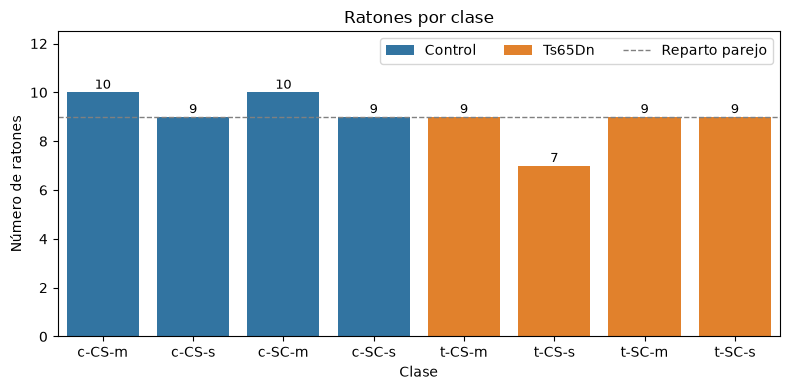

In [6]:
# Ratones por clase, coloreados por genotipo; la línea marca el reparto parejo (72 / 8 = 9)
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=tabla_clases.reset_index(), x=OBJETIVO, y="ratones", hue="genotipo", dodge=False, ax=ax)
ax.axhline(df[GRUPO].nunique() / len(CLASES), color="gray", linestyle="--", linewidth=1, label="Reparto parejo")
for i, n in enumerate(tabla_clases["ratones"]):
    ax.text(i, n + 0.15, n, ha="center", fontsize=9)
ax.set(title="Ratones por clase", xlabel="Clase", ylabel="Número de ratones", ylim=(0, 12.5))
ax.legend(title=None, loc="upper right", ncol=3)
fig.tight_layout()
fig.savefig(FIGURAS / "clases_ratones.png", dpi=150)
plt.show()

**Interpretación:** siete de las ocho clases están balanceadas, con entre 9 y 10 ratones y entre el 12,3 % y el 13,9 % de las réplicas. La excepción es `t-CS-s`, los ratones trisómicos estimulados para aprender y tratados con salina, que tiene 7 ratones y el 9,7 % de las réplicas, es decir, 0,7 veces la clase más grande. Vale la pena notar que esta clase es justamente la del aprendizaje fallido (Ahmed et al., 2015), de modo que es una de las más relevantes para la pregunta del notebook. 

Aun así, el desbalance es leve, por lo que no se justifica remuestrear; además, sobremuestrear réplicas de solo 7 ratones repetiría la información de los mismos individuos. En cambio, el desbalance se atiende de tres formas. Primero, la partición y la validación se estratifican por clase. Segundo, las métricas se reportan con promedio macro, para que `t-CS-s` pese lo mismo que las demás clases. Tercero, se prueba `class_weight="balanced"` como un hiperparámetro más en los modelos que lo admiten. 

Por otra parte, el desbalance tiene una consecuencia en la evaluación final: con 14 ratones en prueba, es probable que `t-CS-s` quede representada por un solo ratón, de modo que su recall en prueba solo podrá tomar unos pocos valores. Por eso, las métricas por clase se interpretan principalmente en la validación cruzada.

## 2. Partición, estrategia de validación y línea base

### 2.1 Conjunto de prueba

Se separa cerca del 20 % de los ratones como conjunto de prueba, que no se vuelve a usar hasta la sección 8. Como las 15 réplicas de un ratón no son independientes, la partición agrupa por individuo, de modo que ninguna réplica de un ratón de prueba participe en el entrenamiento (Roberts et al., 2017); además, se estratifica por clase para que las 8 condiciones experimentales estén representadas en ambos conjuntos. Se usa la misma partición de la Actividad 2 (misma base, misma estratificación y misma semilla), por lo que los ratones de prueba son los mismos en las dos actividades.

In [7]:
# Primer pliegue de la división agrupada y estratificada = conjunto de prueba (igual que en la Actividad 2)
sgfk = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
idx_train, idx_test = next(sgfk.split(df, df[OBJETIVO], groups=df[GRUPO]))

train = df.iloc[idx_train]
test = df.iloc[idx_test]

# Ningún ratón en ambos conjuntos y todas las clases en prueba
assert set(train[GRUPO]).isdisjoint(test[GRUPO])
assert test[OBJETIVO].nunique() == len(CLASES)

print(f"Entrenamiento: {len(train)} filas, {train[GRUPO].nunique()} ratones")
print(f"Prueba: {len(test)} filas, {test[GRUPO].nunique()} ratones")
test.groupby(OBJETIVO, observed=True)[GRUPO].nunique()

Entrenamiento: 867 filas, 58 ratones
Prueba: 210 filas, 14 ratones


class
c-CS-m    2
c-CS-s    2
c-SC-m    2
c-SC-s    2
t-CS-m    2
t-CS-s    1
t-SC-m    1
t-SC-s    2
Name: raton, dtype: int64

**Interpretación:** la partición deja 58 ratones (867 réplicas) en entrenamiento y 14 ratones (210 réplicas) en prueba, sin ningún ratón compartido entre los dos conjuntos. Las 8 clases están en prueba, aunque con solo uno o dos ratones cada una: `t-CS-s` y `t-SC-m` quedan representadas por un único ratón. En consecuencia, en la sección 8 un solo animal mal clasificado puede llevar el recall de esas clases de 1 a 0, de modo que las métricas por clase en prueba se leen como una confirmación, y la evaluación principal se hace con la validación cruzada.

### 2.2 Estrategia de validación

Dentro del entrenamiento, la validación cruzada cumple el papel del conjunto de validación: cada pliegue se usa una vez para evaluar un modelo ajustado con los otros cuatro, por lo que no hace falta separar un tercer conjunto, que con 58 ratones dejaría muy pocos animales para entrenar. A diferencia de la Actividad 2, donde bastaba con `GroupKFold` porque `pERK_N` es continua, aquí se usa `StratifiedGroupKFold`: además de agrupar por ratón, reparte las clases entre los pliegues, de modo que cada pliegue de validación tenga ratones de las 8 clases. Sin la estratificación, algunos pliegues quedarían sin una o dos clases, el AUC uno contra el resto no se podría calcular en ellos y el recall de la clase ausente quedaría indefinido.

In [8]:
# Predictores (solo proteínas), objetivo y grupos de cada conjunto
X_train, y_train, grupos_train = train[PROTEINAS], train[OBJETIVO], train[GRUPO]
X_test, y_test, grupos_test = test[PROTEINAS], test[OBJETIVO], test[GRUPO]

# Validación cruzada en entrenamiento: agrupada por ratón y estratificada por clase
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

# Ratones de cada clase en cada pliegue de validación; ninguna clase puede faltar
ratones_pliegue = pd.DataFrame({
    f"Pliegue {i}": train.iloc[idx_val].groupby(OBJETIVO, observed=True)[GRUPO].nunique()
    for i, (_, idx_val) in enumerate(cv.split(X_train, y_train, groups=grupos_train), start=1)
})
assert ratones_pliegue.notna().all().all(), "Algún pliegue de validación no tiene todas las clases"
ratones_pliegue

,Pliegue 1,Pliegue 2,Pliegue 3,Pliegue 4,Pliegue 5
class,,,,,
c-CS-m,2,2,2,1,1
c-CS-s,2,2,1,1,1
c-SC-m,2,1,2,2,1
c-SC-s,1,1,1,2,2
t-CS-m,1,2,1,1,2
t-CS-s,1,2,1,1,1
t-SC-m,2,1,2,1,2
t-SC-s,1,1,2,2,1


**Interpretación:** los 5 pliegues de validación tienen las 8 clases, con uno o dos ratones por clase y entre 11 y 12 ratones por pliegue. Así, todas las métricas se pueden calcular en cada pliegue, y la variación entre pliegues refleja el desempeño del modelo frente a ratones nuevos y no la ausencia de alguna clase. Este mismo objeto `cv`, con `groups=grupos_train`, se usa en la línea base, en la comparación de la fuga (sección 3) y en todas las búsquedas de hiperparámetros.

### 2.3 Métricas de evaluación

Cada métrica se calcula en los 5 pliegues y se resume como media ± desviación estándar; igual que en la Actividad 2, el ± es la variación entre pliegues y no un intervalo de confianza. Las métricas por clase se promedian con el promedio macro, de modo que cada clase pesa lo mismo sin importar su número de réplicas. El promedio micro no se incluye porque, en un problema multiclase donde cada réplica tiene una sola etiqueta, coincide con la exactitud. Además del desempeño, se evalúan las probabilidades con el log loss y el puntaje de Brier, que mide a la vez la
exactitud y la calibración de las probabilidades (Brier, 1950). Como scikit-learn siempre maximiza el puntaje, devuelve estas dos pérdidas con signo negativo (`neg_`), y la función `resumir_cv` les devuelve su signo original.

In [9]:
# Métricas por pliegue (macro: cada clase pesa igual); las neg_ salen con signo negativo
METRICAS = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
    "auc_ovr": "roc_auc_ovr",
    "log_loss": "neg_log_loss",
    "brier": "neg_brier_score",
}

def resumir_cv(resultados, nombre, parte="test"):
    """Media ± desviación estándar entre pliegues; las métricas neg_ vuelven a su signo original."""
    resumen = {}
    for metrica, scorer in METRICAS.items():
        valores = resultados[f"{parte}_{metrica}"]
        if scorer.startswith("neg_"):
            valores = -valores
        resumen[metrica] = f"{valores.mean():.3f} ± {valores.std():.3f}"
    return pd.Series(resumen, name=nombre)

### 2.4 Línea base

¿Qué desempeño se obtiene sin usar la información de las proteínas? La estrategia `prior` predice siempre la clase más frecuente y asigna a cada clase su proporción como probabilidad, de modo que sirve de referencia para las métricas de probabilidad. La estrategia `stratified`, en cambio, predice al azar respetando las proporciones de las clases, por lo que sirve de referencia para las métricas por clase.

In [10]:
# Líneas base: sin información de las proteínas
linea_base = {
    "Línea base (prior)": DummyClassifier(strategy="prior"),
    "Línea base (stratified)": DummyClassifier(strategy="stratified", random_state=SEMILLA),
}

tabla_cv = pd.DataFrame([
    resumir_cv(cross_validate(modelo, X_train, y_train, groups=grupos_train, cv=cv, scoring=METRICAS), nombre)
    for nombre, modelo in linea_base.items()
])
tabla_cv.T

,Línea base (prior),Línea base (stratified)
accuracy,0.120 ± 0.039,0.110 ± 0.012
balanced_accuracy,0.125 ± 0.000,0.115 ± 0.019
precision_macro,0.015 ± 0.005,0.115 ± 0.016
recall_macro,0.125 ± 0.000,0.115 ± 0.019
f1_macro,0.027 ± 0.008,0.110 ± 0.016
auc_ovr,0.500 ± 0.000,0.494 ± 0.011
log_loss,2.106 ± 0.022,32.083 ± 0.424
brier,0.881 ± 0.005,1.780 ± 0.024


**Interpretación:** las dos líneas base quedan en el nivel del azar para 8 clases. Con `stratified`, la exactitud (0,110) y el F1 macro (0,110) están cerca de 1/8 = 0,125, y el AUC uno contra el resto (0,494) está cerca de 0,5, lo que indica que sus predicciones no ordenan las clases mejor que el azar. Por su parte, `prior` obtiene la misma exactitud, pero su F1 macro cae a 0,027, porque solo predice una de las 8 clases y las otras siete quedan con precisión y recall iguales a 0. Además, su desviación es 0 en la exactitud balanceada, el recall y el AUC, ya que siempre hace la misma predicción con las mismas probabilidades. 

Por otro lado, las métricas de probabilidad muestran por qué hacen falta las dos referencias. Como `prior` asigna a cada clase su proporción, su log loss (2,106) y su Brier (0,881) quedan muy cerca de los valores de un modelo que asigna 1/8 a cada clase (ln 8 ≈ 2,079 y 0,875). En cambio, `stratified` asigna probabilidad 1 a una clase elegida al azar, por lo que cada error le cuesta mucho y su log loss se dispara a 32,083. En consecuencia, un modelo útil debe superar un F1 macro de 0,110 y quedar por debajo de un log loss de 2,106 y de un Brier de 0,881.

## 3. Preprocesamiento y efecto de la fuga 

### 3.1 Pipeline de preprocesamiento 

Todas las proteínas reciben el mismo preprocesamiento que M2 en la Actividad 2, encadenado en un `Pipeline` para que cada paso se ajuste solo con los ratones de entrenamiento de cada pliegue y luego se aplique, con `transform`, a los de validación (Kuhn & Johnson, 2019). Primero, el logaritmo reduce la asimetría de las proteínas y acerca sus órdenes de magnitud, como se decidió en la sección 4.7 de la Actividad 2. Luego, `StandardScaler` lleva cada proteína a media 0 y desviación 1, y por último `KNNImputer` completa los faltantes de las 8 proteínas con ausencia en bloque a partir de los ratones de perfil más parecido, como se decidió en la Actividad 1. 

El escalado no cambia las métricas por sí mismo; lo que cambia es la forma en que aprenden algunos modelos. Por un lado, KNN, la SVM con kernel RBF y el propio `KNNImputer` se basan en distancias, de modo que sin escalar dominarían las proteínas de mayor varianza y las demás casi no influirían en la distancia. Por otro lado, la regresión logística de scikit-learn tiene por defecto una penalización L2, que depende de la magnitud de los coeficientes y, por tanto, de la escala de cada proteína; sin escalar, la penalización afectaría a unas proteínas más que a otras (James et al., 2023). En cambio, los árboles y sus ensambles dividen cada variable por umbrales, así que el escalado no los afecta, pero se mantiene para que todos los modelos reciban exactamente los mismos datos.

In [11]:
# Mismo preprocesamiento de M2 en la Actividad 2: log → escalado → imputación KNN
def crear_pipeline(modelo):
    """Pipeline completo; cada paso se ajusta solo con los datos de entrenamiento de cada pliegue."""
    return Pipeline([
        ("log", FunctionTransformer(np.log, feature_names_out="one-to-one")),
        ("escala", StandardScaler()),
        ("imputa", KNNImputer()),
        ("modelo", modelo),
    ])

### 3.2 Efecto de la fuga

¿Cuánto cambia el desempeño si la validación reparte las réplicas por filas en lugar de por ratón? Para aislar el efecto de la forma de validar, se evalúan la regresión logística y KNN con sus hiperparámetros por defecto, con el mismo `Pipeline` en los dos esquemas.

In [12]:
# Efecto de la fuga: misma validación, repartiendo por filas o por ratón
cv_filas = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

modelos_fuga = {
    "Regresión logística": LogisticRegression(max_iter=5000),
    "KNN (k = 5)": KNeighborsClassifier(n_neighbors=5),
}

filas_fuga = []
for nombre, modelo in modelos_fuga.items():
    for esquema, validacion in {"Por filas": cv_filas, "Por ratón": cv}.items():
        resultados = cross_validate(crear_pipeline(modelo), X_train, y_train,
                                    groups=grupos_train, cv=validacion, scoring=METRICAS)
        filas_fuga.append(resumir_cv(resultados, f"{nombre} · {esquema}"))

tabla_fuga = pd.DataFrame(filas_fuga)
tabla_fuga[["accuracy", "balanced_accuracy", "f1_macro", "auc_ovr", "log_loss", "brier"]]

,accuracy,balanced_accuracy,f1_macro,auc_ovr,log_loss,brier
Regresión logística · Por filas,0.991 ± 0.008,0.991 ± 0.008,0.991 ± 0.008,1.000 ± 0.000,0.067 ± 0.018,0.022 ± 0.010
Regresión logística · Por ratón,0.559 ± 0.117,0.579 ± 0.102,0.510 ± 0.116,0.885 ± 0.061,2.063 ± 0.900,0.689 ± 0.190
KNN (k = 5) · Por filas,0.982 ± 0.004,0.982 ± 0.004,0.981 ± 0.004,1.000 ± 0.000,0.083 ± 0.006,0.046 ± 0.004
KNN (k = 5) · Por ratón,0.408 ± 0.079,0.434 ± 0.065,0.378 ± 0.083,0.744 ± 0.050,14.508 ± 3.370,0.935 ± 0.154


**Interpretación:** cuando la validación reparte por filas, los dos modelos parecen casi perfectos: la exactitud llega a 0,991 en la regresión logística y a 0,982 en KNN, con un AUC de 1,000 en ambos. Sin embargo, al validar por ratón, la exactitud cae a 0,559 y 0,408, es decir, entre 43 y 57 puntos menos. Esta diferencia se debe a la fuga por pseudorreplicación: como las 15 réplicas de un ratón son casi idénticas, al repartir por filas casi siempre quedan réplicas del mismo animal en entrenamiento y en validación, de modo que el modelo no reconoce la condición experimental, sino al individuo (Roberts et al., 2017). Por eso KNN es el más afectado, ya que con validación por filas sus vecinos más cercanos suelen ser réplicas del mismo ratón. En consecuencia, todo el resto del notebook valida por ratón, y los valores de esta validación son el punto de partida real que deben superar los modelos de la sección 4. 

Por otra parte, como el desbalance de clases es leve, la exactitud es una métrica razonable en este problema: en la regresión logística por ratón, la exactitud (0,559), la exactitud balanceada (0,579) y el F1 macro (0,510) quedan cerca entre sí. Aun así, el F1 macro es algo menor, lo que indica que algunas clases se predicen peor que otras, y por eso se mantiene como métrica para elegir los hiperparámetros. Además, el AUC por ratón se mantiene alto, sobre todo en la regresión logística (0,885 frente a 0,744 de KNN). Esto quiere decir que, aunque la clase correcta no siempre queda en el primer lugar entre ocho, el modelo suele asignarle una probabilidad mayor que a las demás, de modo que el perfil de proteínas sí contiene información sobre la condición experimental. 

Las métricas de probabilidad agregan un matiz. Por ratón, el Brier de la regresión logística (0,689) mejora el de la línea base (0,881), pero su log loss (2,063) apenas la iguala (2,106), lo que sugiere que se equivoca con probabilidades muy altas en algunos ratones. KNN es aún más extremo: con k = 5, la probabilidad de cada clase es la proporción de vecinos de esa clase, así que muchas veces le asigna 0 a la clase correcta, y su log loss sube a 14,508 y su Brier a 0,935, peor que la línea base. Este comportamiento se revisa en la calibración de la sección 5. Por último, la desviación entre pliegues por ratón (± 0,117 en la exactitud de la logística) es mucho mayor que por filas, porque cada pliegue tiene solo 11 o 12 ratones y un solo animal mal clasificado cambia la exactitud en varios puntos. 

Vale la pena distinguir esta fuga de la fuga por preprocesamiento. Ajustar el escalado o la imputación con todos los datos y luego evaluar también filtraría información de validación hacia el entrenamiento, pero esa fuga ya está controlada en los dos esquemas, porque el `Pipeline` ajusta cada paso solo con el entrenamiento de cada pliegue y lo aplica con `transform` a la validación (Kuhn & Johnson, 2019). Por lo tanto, la diferencia de la tabla se debe únicamente a la pseudorreplicación.

## 4. Modelos y búsqueda de hiperparámetros 

Se comparan seis clasificadores de naturaleza distinta, todos con el mismo `Pipeline` de la sección 3, la misma validación agrupada por ratón y la misma métrica para elegir hiperparámetros, de modo que ninguno compite con ventaja (James et al., 2023). Para cada modelo, `GridSearchCV` (o `RandomizedSearchCV` en los ensambles, donde la grilla completa sería muy costosa) evalúa cada combinación en los 5 pliegues de `cv`, registra las 8 métricas de `METRICAS` y elige la combinación con mayor F1 macro de validación. Además, como el desbalance de `t-CS-s` es leve, `class_weight="balanced"` entra como un hiperparámetro más en los modelos que lo admiten, en lugar de remuestrear. 

La función `buscar_hiperparametros` repite este procedimiento para todos los modelos: grafica el F1 macro de entrenamiento y de validación frente al hiperparámetro principal, con los demás fijos en su mejor valor, y advierte si algún hiperparámetro numérico quedó en el borde de su grilla, como se hizo en la Actividad 2.

In [13]:
def formato(valor):
    """Texto corto de un hiperparámetro: 4 cifras para los decimales y None para los vacíos."""
    if valor is None or (isinstance(valor, float) and np.isnan(valor)):
        return "None"
    return f"{valor:.4g}" if isinstance(valor, (float, np.floating)) else str(valor)


def buscar_hiperparametros(modelo, grilla, nombre, archivo, parametro, escala_log=False, n_iter=None):
    """Busca los hiperparámetros de un clasificador con validación agrupada por ratón y grafica
    el F1 macro de entrenamiento y validación frente al hiperparámetro principal."""
    opciones = dict(cv=cv, scoring=METRICAS, refit="f1_macro", return_train_score=True, n_jobs=-1)
    if n_iter is None:
        busqueda = GridSearchCV(crear_pipeline(modelo), grilla, **opciones)
    else:
        busqueda = RandomizedSearchCV(crear_pipeline(modelo), grilla, n_iter=n_iter,
                                      random_state=SEMILLA, **opciones)
    busqueda.fit(X_train, y_train, groups=grupos_train)

    resultados = pd.DataFrame(busqueda.cv_results_)
    de_mejor = resultados.loc[busqueda.best_index_, "std_test_f1_macro"]
    clave = f"modelo__{parametro}"
    mejor = busqueda.best_params_[clave]

    # En la grilla completa, la curva fija los demás hiperparámetros en su mejor valor; en la búsqueda
    # aleatoria esas combinaciones casi nunca existen, así que se toma la mejor combinación de cada valor
    if n_iter is None:
        for p, valor in busqueda.best_params_.items():
            if p != clave:
                resultados = resultados[resultados[f"param_{p}"].map(formato) == formato(valor)]
    else:
        valor_txt = resultados[f"param_{clave}"].map(formato)
        resultados = resultados.loc[resultados.groupby(valor_txt)["mean_test_f1_macro"].idxmax()]

    elegidos = ", ".join(f"{p.split('__')[-1]} = {formato(v)}" for p, v in busqueda.best_params_.items())
    print(f"{nombre} · {elegidos} | F1 macro de validación: {busqueda.best_score_:.3f} ± {de_mejor:.3f}")

    # Advertencia si un hiperparámetro numérico con más de dos valores quedó en el extremo de su grilla
    for p, valor in busqueda.best_params_.items():
        numeros = [v for v in grilla[p] if isinstance(v, (int, float, np.number)) and not isinstance(v, bool)]
        if valor in numeros and len(numeros) > 2 and valor in (min(numeros), max(numeros)):
            print(f"Advertencia: {p.split('__')[-1]} quedó en el borde de la grilla; conviene ampliarla.")

    # Eje numérico si todos los valores son números; si hay texto o None, un punto por valor en el orden de la grilla
    etiquetas = resultados[f"param_{clave}"].map(formato)
    numerico = pd.to_numeric(etiquetas, errors="coerce").notna().all()
    if numerico:
        resultados = resultados.assign(x=etiquetas.astype(float).values).sort_values("x")
        x, x_mejor = resultados["x"], float(mejor)
    else:
        x, x_mejor = np.arange(len(etiquetas)), list(etiquetas).index(formato(mejor))

    fig, ax = plt.subplots(figsize=(8, 5))
    for parte, etiqueta in [("train", "Entrenamiento"), ("test", "Validación")]:
        media, de = resultados[f"mean_{parte}_f1_macro"], resultados[f"std_{parte}_f1_macro"]
        ax.plot(x, media, marker="o", label=etiqueta)
        ax.fill_between(x, media - de, media + de, alpha=0.2)
    ax.axvline(x_mejor, color="gray", linestyle="--", label=f"{parametro} elegido = {formato(mejor)}")
    if not numerico:
        ax.set_xticks(x, etiquetas)
    if escala_log:
        ax.set_xscale("log")
    ax.set(title=f"{nombre} · F1 macro frente a {parametro}", ylabel="F1 macro",
           xlabel=f"{parametro} (escala log)" if escala_log else parametro)
    ax.legend()
    fig.savefig(FIGURAS / archivo, dpi=150, bbox_inches="tight")
    plt.show()
    return busqueda

### 4.1 Modelos lineales y basados en distancia 

La regresión logística multinomial estima una frontera lineal entre clases en la escala logarítmica de las proteínas, y `C` controla su penalización L2: con un C pequeño la penalización es fuerte y los coeficientes se encogen (James et al., 2023). Por su parte, KNN clasifica cada réplica según la clase de sus k vecinos más cercanos, sin suponer ninguna forma de frontera (Cover & Hart, 1967); con `weights="distance"`, los vecinos más cercanos pesan más.

Regresión logística · C = 35.11, class_weight = None | F1 macro de validación: 0.516 ± 0.125


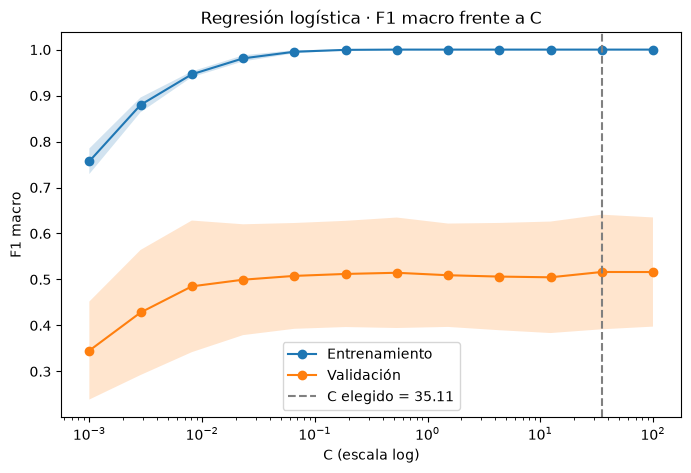

In [14]:
# Regresión logística multinomial: C es el inverso de la penalización L2
busqueda_rl = buscar_hiperparametros(
    LogisticRegression(max_iter=5000),
    {"modelo__C": np.logspace(-3, 2, 12), "modelo__class_weight": [None, "balanced"]},
    "Regresión logística", "rl_C.png", parametro="C", escala_log=True)

KNN · n_neighbors = 11, weights = distance | F1 macro de validación: 0.384 ± 0.100


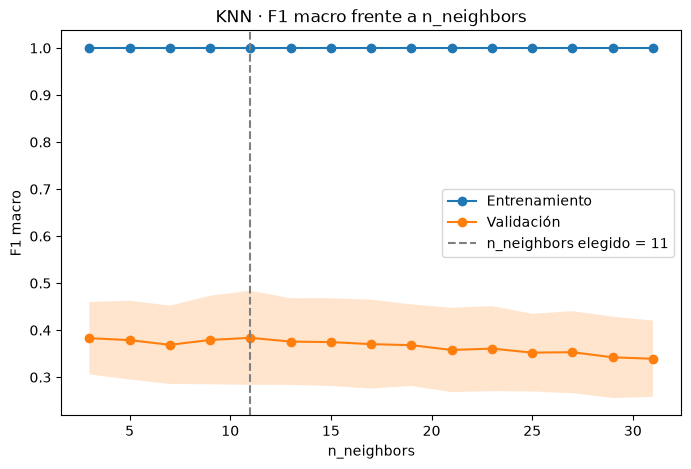

In [15]:
# KNN: número de vecinos y peso de cada vecino
busqueda_knn = buscar_hiperparametros(
    KNeighborsClassifier(),
    {"modelo__n_neighbors": list(range(3, 32, 2)), "modelo__weights": ["uniform", "distance"]},
    "KNN", "knn_k.png", parametro="n_neighbors")

**Interpretación:** la regresión logística alcanza un F1 macro de validación de 0,516 ± 0,125 con C = 35,1 y sin ponderar las clases. Sin embargo, su curva de validación es casi plana desde C ≈ 0,1, mientras que el F1 de entrenamiento llega a 1: penalizar más reduce el ajuste al entrenamiento, pero no mejora la validación. Esto indica que la brecha entre las dos curvas no se debe a un exceso de complejidad que la regularización pueda corregir, sino a que el modelo aprende a los 46 ratones de cada pliegue de entrenamiento, cuyas réplicas son casi idénticas, y luego debe generalizar a ratones nuevos. Además, como las diferencias entre los valores de C de la meseta son mucho menores que la variación entre pliegues, cualquier C entre 0,1 y 100 sería equivalente según la regla de una desviación estándar (James et al., 2023). 

Por su parte, KNN queda muy por debajo, con un F1 macro de 0,384 ± 0,100 y k = 11. Su F1 de entrenamiento es 1 para todo k, pero ese valor no indica un buen ajuste: con `weights="distance"`, cada réplica es su propio vecino a distancia 0. Además, su validación baja levemente a medida que k crece, porque con más vecinos se mezclan réplicas de otras clases. En resumen, en 76 dimensiones las distancias entre réplicas de ratones distintos son poco informativas, lo que hace a KNN el modelo más débil del grupo.

### 4.2 Árbol de decisión

El árbol divide las réplicas con umbrales sucesivos sobre una proteína a la vez, de modo que su resultado se puede leer como un conjunto de reglas (Breiman et al., 1984). Sin embargo, un árbol profundo memoriza el entrenamiento, por lo que la profundidad máxima y el tamaño mínimo de las hojas controlan su complejidad.

Árbol de decisión · class_weight = None, max_depth = 4, min_samples_leaf = 20 | F1 macro de validación: 0.480 ± 0.039


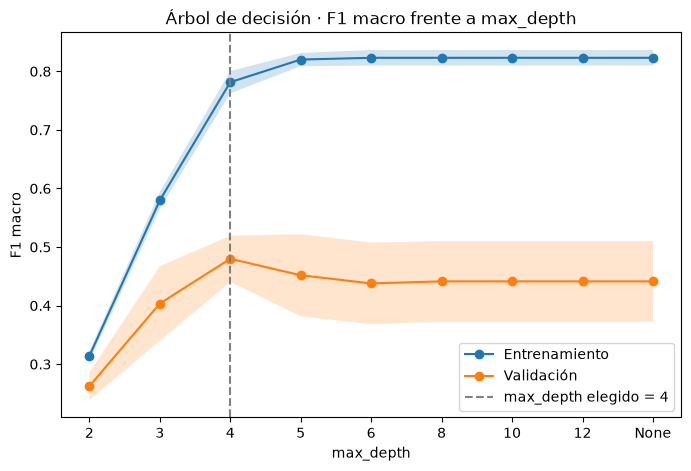

In [16]:
# Árbol de decisión: profundidad máxima y tamaño mínimo de las hojas
busqueda_arbol = buscar_hiperparametros(
    DecisionTreeClassifier(random_state=SEMILLA),
    {"modelo__max_depth": [2, 3, 4, 5, 6, 8, 10, 12, None], "modelo__min_samples_leaf": [1, 5, 10, 20, 40],
     "modelo__class_weight": [None, "balanced"]},
    "Árbol de decisión", "arbol_profundidad.png", parametro="max_depth")

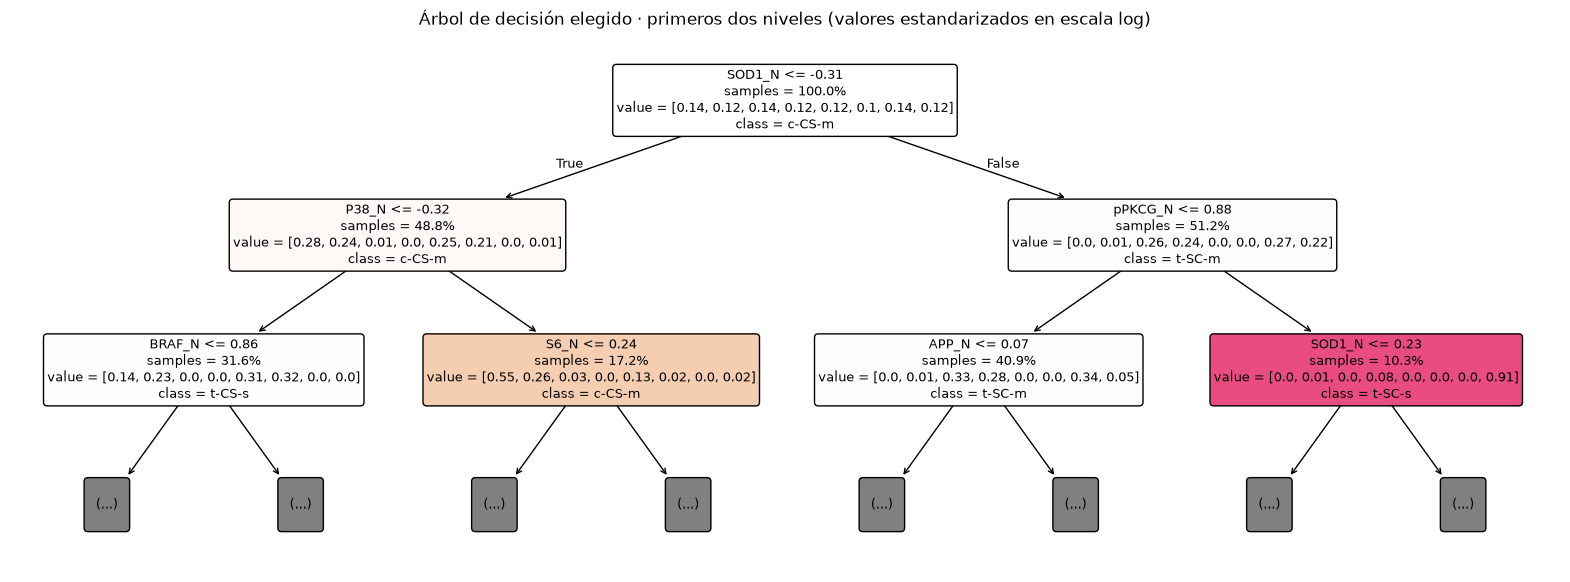

In [17]:
# Primeros dos niveles del árbol elegido: qué proteínas usa para las primeras divisiones
arbol = busqueda_arbol.best_estimator_.named_steps["modelo"]
fig, ax = plt.subplots(figsize=(20, 7))
plot_tree(arbol, max_depth=2, feature_names=PROTEINAS, class_names=CLASES, filled=True,
          impurity=False, proportion=True, precision=2, rounded=True, fontsize=9, ax=ax)
ax.set_title("Árbol de decisión elegido · primeros dos niveles (valores estandarizados en escala log)")
fig.savefig(FIGURAS / "arbol_niveles.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:** el árbol de decisión elige una profundidad de 4 con hojas de al menos 20 réplicas, con un F1 macro de 0,480 ± 0,039. Su curva muestra la forma clásica del sobreajuste: la validación sube hasta una profundidad de 4 y luego baja, mientras el entrenamiento sigue subiendo, por lo que en este caso sí hay un nivel de complejidad que generaliza mejor (Breiman et al., 1984). Además, es el modelo con menor desviación entre pliegues, ya que unas pocas reglas cambian menos de un pliegue a otro que una frontera con 76 proteínas. 

Los primeros niveles del árbol también son informativos. La primera división usa `SOD1_N`, y separa casi por completo a los ratones estimulados para aprender (CS, a la izquierda) de los no estimulados (SC, a la derecha), de modo que la conducta es lo primero que el árbol distingue. Luego, del lado SC, `pPKCG_N` aísla a los ratones `t-SC-s` en la hoja más pura del segundo nivel (91 % de sus réplicas). Esto coincide con Higuera et al. (2015), que reportan a SOD1 entre las proteínas asociadas al aprendizaje y a pPKCG entre las que responden a la memantina en los ratones trisómicos no estimulados.

### 4.3 Máquina de vectores de soporte 

La SVM busca la frontera con mayor margen entre clases, y con el kernel RBF esa frontera puede ser no lineal (Cortes & Vapnik, 1995). Dos hiperparámetros trabajan juntos: `C` castiga las réplicas que quedan del lado equivocado del margen, y `gamma` define el alcance de cada réplica; con un gamma alto la frontera se vuelve muy irregular, mientras que con un gamma bajo se acerca a una frontera lineal. Como la SVM no produce probabilidades por sí misma, `probability=True` las estima con la escala de Platt sobre una validación interna (Platt, 1999).

SVM (RBF) · C = 100, class_weight = balanced, gamma = 1e-05 | F1 macro de validación: 0.542 ± 0.142


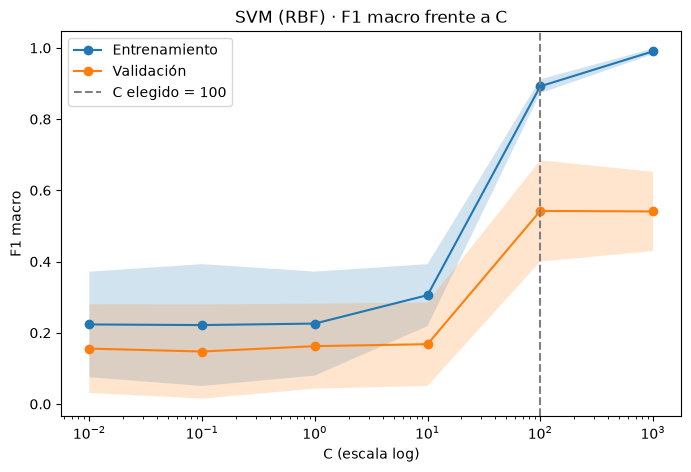

In [18]:
# SVM con kernel RBF: C (penalización de los errores de margen) y gamma (alcance de cada réplica)
# probability=True habilita predict_proba, necesario para el log loss, el Brier y el AUC
busqueda_svm = buscar_hiperparametros(
    SVC(kernel="rbf", probability=True, random_state=SEMILLA),
    {"modelo__C": np.logspace(-2, 3, 6), "modelo__gamma": ["scale", 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1],
     "modelo__class_weight": [None, "balanced"]},
    "SVM (RBF)", "svm_C.png", parametro="C", escala_log=True)

**Interpretación:** la SVM obtiene el F1 macro más alto del grupo, 0,542 ± 0,142, con C = 100, gamma = 0,00001 y clases balanceadas. La combinación es reveladora: un gamma tan pequeño hace que cada réplica influya en una región muy amplia, de modo que la frontera es casi lineal, y el C alto compensa permitiendo pocos errores de margen. En otras palabras, la mejor SVM se comporta como un modelo lineal, lo que coincide con el buen desempeño de la regresión logística. Por otra parte, con C ≤ 10 el modelo casi no aprende (F1 cercano a 0,15), y por encima de C = 100 el entrenamiento llega a 0,99 sin mejorar la validación. Sin embargo, su desviación entre pliegues es la mayor de los seis modelos, como se revisa en la sección 7.

### 4.4 Ensambles de árboles 

El random forest promedia 500 árboles entrenados con muestras bootstrap y con un subconjunto aleatorio de proteínas en cada división, lo que reduce la varianza de un árbol individual (Breiman, 2001). Por eso el número de árboles se deja fijo, ya que más árboles no sobreajustan, y se buscan `max_features` y `min_samples_leaf`. En cambio, el gradient boosting agrega árboles pequeños en secuencia, cada uno corrigiendo los errores del anterior (Friedman, 2001), de modo que la tasa de aprendizaje, el número de iteraciones y el tamaño de los árboles se buscan juntos. Se fija `early_stopping=False`, porque la parada temprana separa una validación interna por filas, que repetiría la fuga por pseudorreplicación de la sección 3.

Random forest · min_samples_leaf = 5, max_features = 0.5, max_depth = None, class_weight = None | F1 macro de validación: 0.512 ± 0.060
Advertencia: max_features quedó en el borde de la grilla; conviene ampliarla.


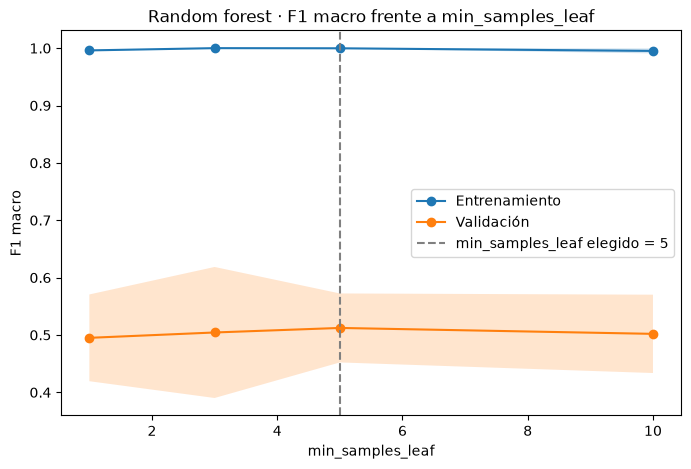

In [19]:
# Random forest: 500 árboles fijos; se buscan las proteínas por división y el tamaño de las hojas
busqueda_rf = buscar_hiperparametros(
    RandomForestClassifier(n_estimators=500, random_state=SEMILLA),
    {"modelo__max_features": ["sqrt", 0.05, 0.1, 0.3, 0.5], "modelo__min_samples_leaf": [1, 3, 5, 10],
     "modelo__max_depth": [None, 5, 10], "modelo__class_weight": [None, "balanced"]},
    "Random forest", "rf_hojas.png", parametro="min_samples_leaf", n_iter=20)

Gradient boosting · max_leaf_nodes = 15, max_iter = 100, learning_rate = 0.3, l2_regularization = 1, class_weight = balanced | F1 macro de validación: 0.518 ± 0.106


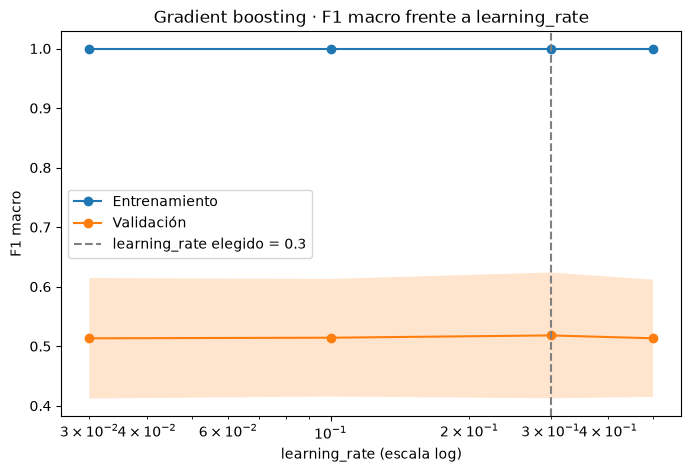

In [20]:
# Gradient boosting: early_stopping=False evita una validación interna por filas (fuga por pseudorreplicación)
busqueda_hgb = buscar_hiperparametros(
    HistGradientBoostingClassifier(early_stopping=False, random_state=SEMILLA),
    {"modelo__learning_rate": [0.03, 0.1, 0.3, 0.5], "modelo__max_iter": [100, 300],
     "modelo__max_leaf_nodes": [7, 15, 31], "modelo__l2_regularization": [0.0, 1.0],
     "modelo__class_weight": [None, "balanced"]},
    "Gradient boosting", "hgb_tasa.png", parametro="learning_rate", escala_log=True, n_iter=20)

**Interpretación:** el random forest elige hojas de al menos 5 réplicas y la mitad de las proteínas en cada división (`max_features` = 0,5), con un F1 macro de 0,512 ± 0,060, la menor desviación entre los modelos con F1 mayor que 0,5. Este valor quedó en el máximo de la grilla, pero no se amplió: con valores más altos cada división consideraría casi todas las proteínas, los árboles se parecerían entre sí y el ensamble perdería la decorrelación que lo distingue del bagging (Breiman, 2001). Como la búsqueda es aleatoria, su gráfico muestra la mejor combinación encontrada para cada tamaño de hoja. 

Por su parte, el gradient boosting obtiene 0,518 ± 0,106 con una tasa de aprendizaje de 0,3, 100 iteraciones, árboles de 15 hojas y clases balanceadas. Su F1 de entrenamiento es 1 para todas las tasas, mientras que la validación apenas cambia entre 0,03 y 0,3, lo que repite el patrón de la regresión logística: el modelo memoriza a los ratones de entrenamiento sin que eso mejore ni empeore la predicción de ratones nuevos.

### 4.5 Resumen de la búsqueda

Cada búsqueda deja el mejor estimador ya reajustado con todo el entrenamiento (`refit`), que es el que se evalúa en
las secciones siguientes.

In [21]:
# Mejor estimador de cada búsqueda (ya reajustado con todo el entrenamiento por refit)
busquedas = {
    "Regresión logística": busqueda_rl,
    "KNN": busqueda_knn,
    "Árbol de decisión": busqueda_arbol,
    "SVM (RBF)": busqueda_svm,
    "Random forest": busqueda_rf,
    "Gradient boosting": busqueda_hgb,
}
modelos = {nombre: busqueda.best_estimator_ for nombre, busqueda in busquedas.items()}

# Hiperparámetros elegidos por modelo
pd.DataFrame({
    nombre: {p.split("__")[-1]: formato(v) for p, v in busqueda.best_params_.items()}
    for nombre, busqueda in busquedas.items()
}).T.fillna("—")

,C,class_weight,n_neighbors,weights,max_depth,min_samples_leaf,gamma,max_features,max_leaf_nodes,max_iter,learning_rate,l2_regularization
Regresión logística,35.11,None,—,—,—,—,—,—,—,—,—,—
KNN,—,—,11,distance,—,—,—,—,—,—,—,—
Árbol de decisión,—,None,—,—,4,20,—,—,—,—,—,—
SVM (RBF),100,balanced,—,—,—,—,1e-05,—,—,—,—,—
Random forest,—,None,—,—,None,5,—,0.5,—,—,—,—
Gradient boosting,—,balanced,—,—,—,—,—,—,15,100,0.3,1


**Interpretación:** `class_weight="balanced"` solo fue elegido por la SVM y el gradient boosting, mientras que la regresión logística, el árbol y el random forest funcionaron mejor sin ponderar las clases. Esto confirma que el desbalance de `t-CS-s` es leve y que corregirlo no cambia de forma sistemática el desempeño. Por otra parte, todos los modelos eligieron configuraciones de alta capacidad (C grande, árboles profundos, sin límite de profundidad en el random forest), lo que concuerda con que la regularización no cierra la brecha con la validación.

## 5. Métricas en validación cruzada

### 5.1 Comparación de los modelos

Los puntajes por pliegue de la combinación elegida salen directamente de `cv_results_`, sin volver a entrenar, y se resumen igual que la línea base, que se incluye en la misma tabla como referencia.

In [22]:
def resultados_mejor(busqueda):
    """Puntajes por pliegue de la mejor combinación, con el mismo formato que devuelve cross_validate."""
    r, i = busqueda.cv_results_, busqueda.best_index_
    return {
        f"{parte}_{metrica}": np.array([r[f"split{k}_{parte}_{metrica}"][i] for k in range(cv.get_n_splits())])
        for parte in ("train", "test") for metrica in METRICAS
    }


puntajes_cv = {nombre: resultados_mejor(busqueda) for nombre, busqueda in busquedas.items()}

# Métricas de validación de los seis modelos junto a las líneas base
tabla_modelos = pd.concat([pd.DataFrame([resumir_cv(r, n) for n, r in puntajes_cv.items()]), tabla_cv])
tabla_modelos

,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,auc_ovr,log_loss,brier
Regresión logística,0.563 ± 0.117,0.585 ± 0.108,0.546 ± 0.167,0.585 ± 0.108,0.516 ± 0.125,0.884 ± 0.061,3.398 ± 1.516,0.770 ± 0.215
KNN,0.418 ± 0.100,0.442 ± 0.079,0.418 ± 0.140,0.442 ± 0.079,0.384 ± 0.100,0.785 ± 0.056,9.718 ± 3.160,0.818 ± 0.143
Árbol de decisión,0.504 ± 0.044,0.521 ± 0.036,0.516 ± 0.043,0.521 ± 0.036,0.480 ± 0.039,0.842 ± 0.021,4.696 ± 1.863,0.769 ± 0.059
SVM (RBF),0.589 ± 0.158,0.605 ± 0.125,0.552 ± 0.148,0.605 ± 0.125,0.542 ± 0.142,0.875 ± 0.068,1.483 ± 0.529,0.653 ± 0.210
Random forest,0.550 ± 0.067,0.559 ± 0.078,0.540 ± 0.054,0.559 ± 0.078,0.512 ± 0.060,0.901 ± 0.032,1.235 ± 0.173,0.596 ± 0.071
Gradient boosting,0.546 ± 0.123,0.570 ± 0.126,0.543 ± 0.100,0.570 ± 0.126,0.518 ± 0.106,0.844 ± 0.065,1.976 ± 0.406,0.712 ± 0.165
Línea base (prior),0.120 ± 0.039,0.125 ± 0.000,0.015 ± 0.005,0.125 ± 0.000,0.027 ± 0.008,0.500 ± 0.000,2.106 ± 0.022,0.881 ± 0.005
Línea base (stratified),0.110 ± 0.012,0.115 ± 0.019,0.115 ± 0.016,0.115 ± 0.019,0.110 ± 0.016,0.494 ± 0.011,32.083 ± 0.424,1.780 ± 0.024


**Interpretación:** los seis modelos superan con amplitud a la línea base: su F1 macro va de 0,384 (KNN) a 0,542 (SVM), frente a 0,110 de `stratified`, y su AUC va de 0,785 a 0,901, frente a 0,5. Sin embargo, las diferencias entre los cinco mejores en F1 macro (de 0,480 a 0,542) son menores que su variación entre pliegues (entre ± 0,039 y ± 0,142), de modo que el F1 por sí solo no permite separarlos. 

En cambio, las métricas de probabilidad sí los distinguen. El random forest obtiene el mejor AUC (0,901), el menor log loss (1,235) y el menor Brier (0,596), seguido de la SVM (0,875, 1,483 y 0,653). Por el contrario, la regresión logística y el árbol tienen un log loss de 3,398 y 4,696, peor que el de la línea base (2,106), aunque su F1 sea cinco veces mayor: cuando se equivocan, lo hacen asignando una probabilidad muy alta a la clase incorrecta. En el árbol esto ocurre porque las hojas puras asignan probabilidad 1, y en la logística porque un C de 35 casi no penaliza los coeficientes. Así, un modelo puede clasificar bien y, al mismo tiempo, estimar mal sus probabilidades, lo que importa si esas probabilidades se van a usar para decidir (sección 7.4).

### 5.2 Entrenamiento frente a validación

¿Cuánto se aleja el desempeño de entrenamiento del de validación con los hiperparámetros elegidos?

In [23]:
# Sobreajuste: F1 macro de entrenamiento frente a validación con los hiperparámetros elegidos
brecha = pd.DataFrame({
    nombre: {
        "F1 entrenamiento": r["train_f1_macro"].mean(),
        "F1 validación": r["test_f1_macro"].mean(),
        "Brecha": r["train_f1_macro"].mean() - r["test_f1_macro"].mean(),
    }
    for nombre, r in puntajes_cv.items()
}).T.round(3)
brecha

,F1 entrenamiento,F1 validación,Brecha
Regresión logística,1.000,0.516,0.484
KNN,1.000,0.384,0.616
Árbol de decisión,0.781,0.480,0.302
SVM (RBF),0.892,0.542,0.350
Random forest,1.000,0.512,0.487
Gradient boosting,1.000,0.518,0.482


**Interpretación:** con los hiperparámetros elegidos, cuatro de los seis modelos llegan a un F1 de entrenamiento de 1,000, y la brecha con la validación va de 0,302 (árbol) a 0,616 (KNN). Como se discutió en la sección 4, esta brecha no indica por sí sola un sobreajuste corregible: el F1 de entrenamiento se calcula sobre los mismos ratones con los que se ajustó el modelo, cuyas 15 réplicas son casi idénticas, mientras que la validación mide la capacidad de reconocer la condición en ratones nuevos. Por eso, el criterio relevante es la curva de validación de cada búsqueda, y no el tamaño de la brecha; de hecho, los dos modelos con menor brecha (el árbol y la SVM) no son los de mejor desempeño en todas las métricas.

### 5.3 Métricas por clase

Para las métricas por clase, las curvas y la calibración se usan predicciones fuera de pliegue: `cross_val_predict` asigna a cada réplica la probabilidad de un modelo que no vio a su ratón. Estas métricas se calculan sobre las 867 réplicas juntas, por lo que pueden diferir levemente de las medias por pliegue de la sección 5.1.

In [24]:
# Probabilidades fuera de pliegue: cada réplica las recibe de un modelo que no vio a su ratón
probas_cv = {
    nombre: cross_val_predict(modelo, X_train, y_train, groups=grupos_train, cv=cv,
                              method="predict_proba", n_jobs=-1)
    for nombre, modelo in modelos.items()
}

# Las columnas de predict_proba siguen el orden de CLASES
assert all(list(modelo.classes_) == CLASES for modelo in modelos.values())
preds_cv = {nombre: np.array(CLASES)[proba.argmax(axis=1)] for nombre, proba in probas_cv.items()}

# Modelos ordenados por F1 macro de validación; los tres primeros se analizan en detalle
orden = sorted(puntajes_cv, key=lambda n: puntajes_cv[n]["test_f1_macro"].mean(), reverse=True)
mejores = orden[:3]
print("Orden por F1 macro:", orden)

Orden por F1 macro: ['SVM (RBF)', 'Gradient boosting', 'Regresión logística', 'Random forest', 'Árbol de decisión', 'KNN']


In [25]:
# Precisión, recall y F1 por clase de los tres mejores modelos (predicciones fuera de pliegue)
for nombre in mejores:
    print(f"===== {nombre} =====")
    print(classification_report(y_train, preds_cv[nombre], labels=CLASES, digits=3, zero_division=0))

===== SVM (RBF) =====
              precision    recall  f1-score   support

      c-CS-m      0.562     0.608     0.584       120
      c-CS-s      0.121     0.076     0.094       105
      c-SC-m      0.667     0.717     0.691       120
      c-SC-s      0.759     0.600     0.670       105
      t-CS-m      0.331     0.381     0.354       105
      t-CS-s      0.424     0.400     0.411        90
      t-SC-m      0.688     0.642     0.664       120
      t-SC-s      0.709     0.980     0.823       102

    accuracy                          0.557       867
   macro avg      0.532     0.551     0.536       867
weighted avg      0.539     0.557     0.543       867

===== Gradient boosting =====
              precision    recall  f1-score   support

      c-CS-m      0.427     0.417     0.422       120
      c-CS-s      0.226     0.181     0.201       105
      c-SC-m      0.667     0.717     0.691       120
      c-SC-s      0.596     0.648     0.621       105
      t-CS-m      0.344   

**Interpretación:** los tres modelos con mayor F1 macro coinciden en qué clases son fáciles y cuáles difíciles. Las clases no estimuladas (SC) se reconocen mejor: `t-SC-s` alcanza un F1 entre 0,763 y 0,823 (con un recall de 0,980 en la SVM), y `c-SC-m` y `c-SC-s` quedan entre 0,621 y 0,854. En cambio, las clases estimuladas (CS) son las más difíciles: `c-CS-s` tiene un F1 entre 0,094 y 0,201, apenas por encima del azar, y `t-CS-m` entre 0,290 y 0,381. Por otra parte, `t-CS-s`, la clase del aprendizaje fallido y la de menos ratones, no es la más difícil: la regresión logística y el gradient boosting la reconocen con un F1 de 0,685 y 0,637. Esto sugiere que el aprendizaje fallido deja un perfil proteico más distinguible que el aprendizaje normal en los ratones control tratados con salina.

### 5.4 Matrices de confusión

Las matrices se normalizan por la clase real, de modo que cada fila suma 1 y la diagonal es el recall de cada clase.

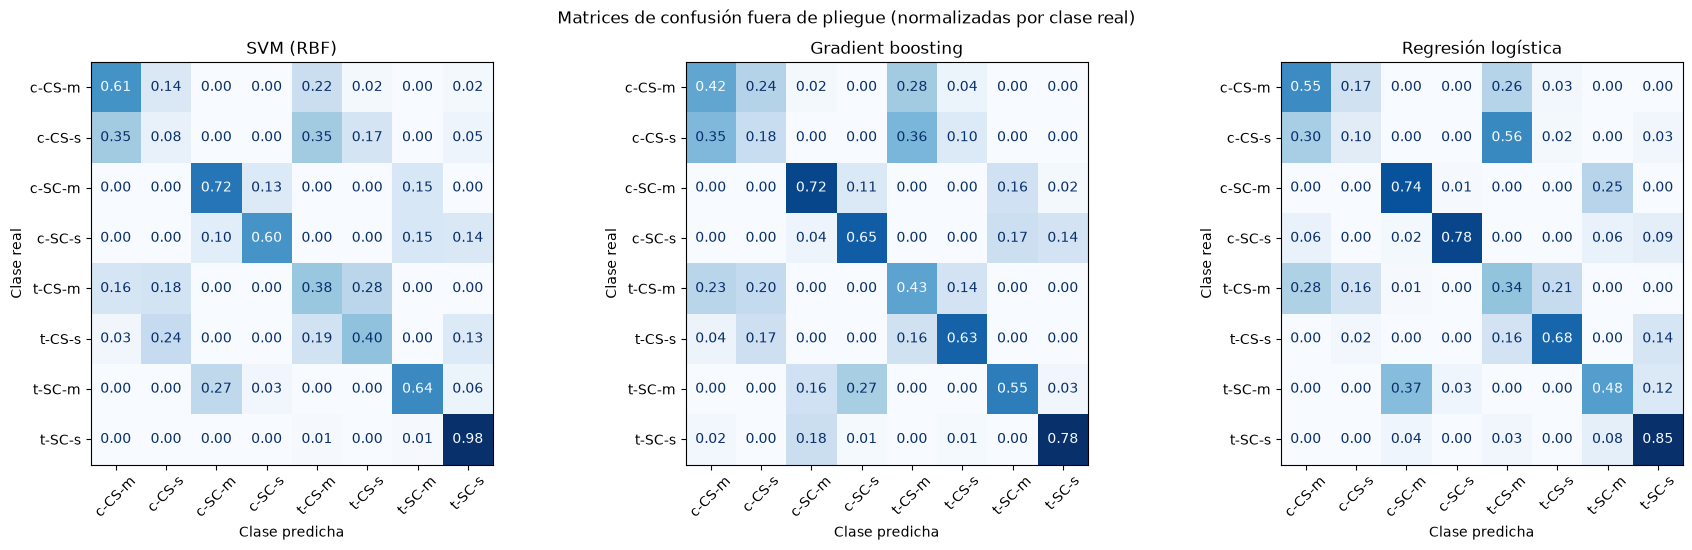

In [26]:
# Matrices de confusión normalizadas por fila: la diagonal es el recall de cada clase
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, nombre in zip(axes, mejores):
    ConfusionMatrixDisplay.from_predictions(
        y_train, preds_cv[nombre], labels=CLASES, normalize="true", values_format=".2f",
        cmap="Blues", colorbar=False, ax=ax)
    ax.set(title=nombre, xlabel="Clase predicha", ylabel="Clase real")
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("Matrices de confusión fuera de pliegue (normalizadas por clase real)")
fig.tight_layout()
fig.savefig(FIGURAS / "confusion_cv.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:** las matrices muestran que los errores no se reparten al azar, sino en dos bloques. Primero, las clases CS casi nunca se confunden con las SC: los cuadrantes que cruzan los dos grupos están prácticamente en 0. Así, los modelos reconocen con claridad si un ratón fue estimulado para aprender. Segundo, dentro de cada grupo, los errores se concentran en el genotipo y el tratamiento. En el grupo CS, `c-CS-s` se confunde con `c-CS-m` (entre 0,30 y 0,35) y con `t-CS-m` (entre 0,35 y 0,56), es decir, con las clases que comparten la conducta y difieren en el tratamiento o en el genotipo. En el grupo SC, `t-SC-m` se confunde con `c-SC-m` (entre 0,16 y 0,37). Esta última confusión, entre ratones trisómicos y control tratados con memantina, es coherente con la idea de que el fármaco acerca el perfil de los trisómicos al de los controles (Ahmed et al., 2015), aunque con estos datos no se puede afirmar como una relación causal.

### 5.5 Curvas ROC y Precisión-Recall

Las curvas se trazan uno contra el resto para el modelo con mayor F1 macro: cada clase se trata como positiva frente a las otras siete. En la curva PR, la referencia del azar es la prevalencia de la clase (cerca de 0,125) y no 0,5 (Saito & Rehmsmeier, 2015).

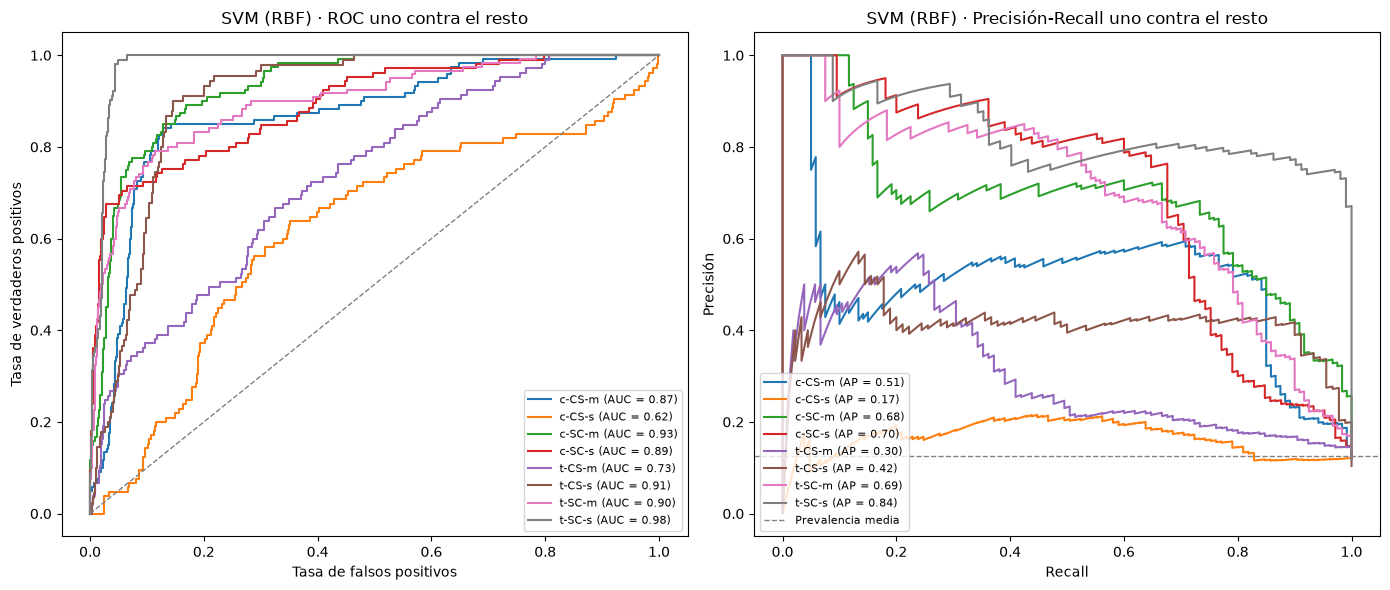

In [27]:
# Curvas ROC y Precisión-Recall uno contra el resto del mejor modelo
mejor = mejores[0]
y_bin = label_binarize(y_train, classes=CLASES)
proba = probas_cv[mejor]

fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(14, 6))
for k, clase in enumerate(CLASES):
    fpr, tpr, _ = roc_curve(y_bin[:, k], proba[:, k])
    ax_roc.plot(fpr, tpr, label=f"{clase} (AUC = {roc_auc_score(y_bin[:, k], proba[:, k]):.2f})")
    precision, recall, _ = precision_recall_curve(y_bin[:, k], proba[:, k])
    ax_pr.plot(recall, precision, label=f"{clase} (AP = {average_precision_score(y_bin[:, k], proba[:, k]):.2f})")

ax_roc.plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1)
ax_roc.set(title=f"{mejor} · ROC uno contra el resto", xlabel="Tasa de falsos positivos",
           ylabel="Tasa de verdaderos positivos")
ax_pr.axhline(y_bin.mean(), color="gray", linestyle="--", linewidth=1, label="Prevalencia media")
ax_pr.set(title=f"{mejor} · Precisión-Recall uno contra el resto", xlabel="Recall", ylabel="Precisión")
for ax in (ax_roc, ax_pr):
    ax.legend(fontsize=8, loc="lower right" if ax is ax_roc else "lower left")
fig.tight_layout()
fig.savefig(FIGURAS / "roc_pr_mejor.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:** en la SVM, el AUC uno contra el resto va de 0,62 (`c-CS-s`) a 0,98 (`t-SC-s`), con seis de las ocho clases en 0,87 o más. Sin embargo, la curva PR muestra un panorama más exigente: la precisión promedio de `c-CS-s` es 0,17, apenas por encima de su prevalencia (≈ 0,12), y la de `t-CS-m` es 0,30, aunque sus AUC de 0,62 y 0,73 parecen aceptables. Esto ocurre porque la ROC se apoya en la tasa de falsos positivos, que se mantiene baja cuando los negativos son siete veces más numerosos que los positivos, mientras que la precisión refleja directamente cuántas de las réplicas que el modelo asigna a la clase realmente lo son (Saito & Rehmsmeier, 2015). Por eso, las dos curvas coinciden en señalar a `c-CS-s` y `t-CS-m` como las clases débiles, pero la PR muestra mejor la magnitud del problema.

### 5.6 Calibración

Un modelo está calibrado cuando, de las réplicas a las que asigna una probabilidad de 0,7, acierta cerca del 70 %. Con 8 clases se evalúa la calibración de la clase predicha: la probabilidad que el modelo asigna a su predicción frente a la proporción real de aciertos, en 5 grupos de igual tamaño (Niculescu-Mizil & Caruana, 2005).

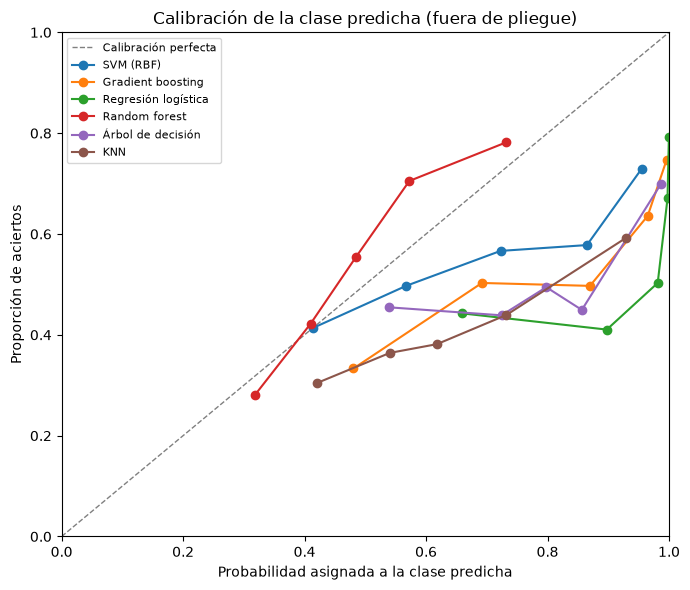

In [28]:
# Calibración de la clase predicha: confianza del modelo frente a la proporción real de aciertos
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1, label="Calibración perfecta")
for nombre in orden:
    proba = probas_cv[nombre]
    acierto = (preds_cv[nombre] == y_train.to_numpy()).astype(int)
    real, confianza = calibration_curve(acierto, proba.max(axis=1), n_bins=5, strategy="quantile")
    ax.plot(confianza, real, marker="o", label=nombre)
ax.set(title="Calibración de la clase predicha (fuera de pliegue)", xlabel="Probabilidad asignada a la clase predicha",
       ylabel="Proporción de aciertos", xlim=(0, 1), ylim=(0, 1))
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURAS / "calibracion_cv.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:** el random forest es el único modelo cuya curva queda por encima de la diagonal: cuando asigna a su predicción una probabilidad cercana a 0,57, acierta en el 70 % de los casos, es decir, es poco confiado. Esto es esperable, porque al promediar 500 árboles sus probabilidades rara vez llegan a los extremos (Niculescu-Mizil & Caruana, 2005). En cambio, los demás modelos quedan por debajo de la diagonal, lo que indica exceso de confianza. El caso más marcado es la regresión logística, que asigna probabilidades cercanas a 1 a predicciones que aciertan entre el 40 % y el 80 % de las veces, lo que explica su log loss de 3,398. La SVM, cuyas probabilidades ya pasan por la escala de Platt, queda más cerca de la diagonal que los demás en el rango medio.

## 6. Clasificación a nivel de ratón

### 6.1 Del nivel de réplica al nivel de ratón

En la práctica se clasifica un animal a partir de sus 15 mediciones, no una réplica aislada. Por eso se promedian las probabilidades fuera de pliegue de las réplicas de cada ratón y se le asigna la clase de mayor probabilidad promedio.

In [29]:
def clasificar_por_raton(proba, y, grupos):
    """Promedia las probabilidades de las réplicas de cada ratón y le asigna la clase más probable."""
    promedio = pd.DataFrame(proba, columns=CLASES, index=y.index).groupby(grupos.to_numpy()).mean()
    real = y.groupby(grupos.to_numpy()).first().loc[promedio.index].astype(str)
    return real, promedio.idxmax(axis=1)


por_raton = {nombre: clasificar_por_raton(proba, y_train, grupos_train) for nombre, proba in probas_cv.items()}

tabla_raton = pd.DataFrame({
    nombre: {
        "Exactitud por réplica": accuracy_score(y_train, preds_cv[nombre]),
        "Exactitud por ratón": accuracy_score(real, pred),
        "F1 macro por ratón": f1_score(real, pred, average="macro"),
        "Ratones bien clasificados": (real == pred).sum(),
    }
    for nombre, (real, pred) in por_raton.items()
}).T.loc[orden]
tabla_raton["Ratones bien clasificados"] = tabla_raton["Ratones bien clasificados"].astype(int)
tabla_raton.round(3)

,Exactitud por réplica,Exactitud por ratón,F1 macro por ratón,Ratones bien clasificados
SVM (RBF),0.557,0.621,0.589,36
Gradient boosting,0.543,0.603,0.599,35
Regresión logística,0.564,0.586,0.577,34
Random forest,0.549,0.603,0.593,35
Árbol de decisión,0.503,0.586,0.572,34
KNN,0.416,0.397,0.362,23


**Interpretación:** al clasificar por ratón, la exactitud mejora en cinco de los seis modelos: la SVM pasa de 0,557 por réplica a 0,621 por ratón (36 de 58 ratones), y el gradient boosting y el random forest llegan a 0,603 (35 de 58). Esto indica que parte de los errores por réplica son ruido técnico entre mediciones del mismo animal, que se compensa al promediar sus 15 réplicas. La excepción es KNN, que empeora (0,397), porque sus probabilidades son proporciones de pocos vecinos y su promedio no corrige los errores sistemáticos. 

La matriz por ratón de la SVM confirma lo visto por réplica. `t-SC-s` queda bien clasificada en sus 7 ratones y `c-CS-m` en 7 de 8, mientras que `c-CS-s` solo acierta en 1 de 7: sus otros 6 ratones se reparten entre `c-CS-m`, `t-CS-m` y `t-CS-s`, todos del grupo CS.

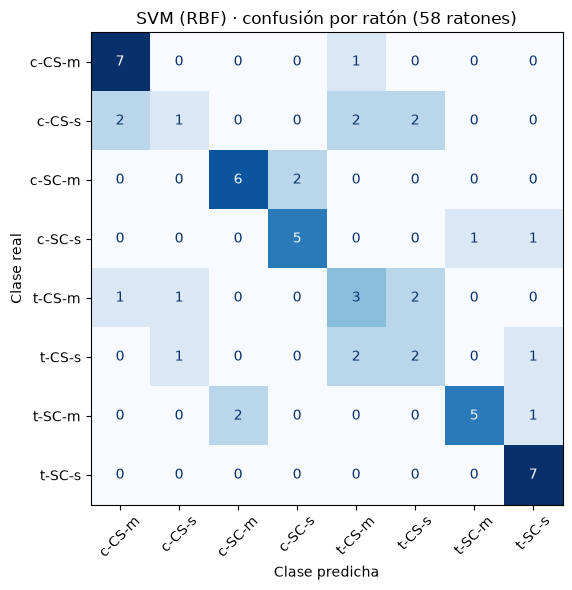

In [30]:
# Matriz de confusión por ratón del mejor modelo (conteos de ratones)
real, pred = por_raton[mejor]
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(real, pred, labels=CLASES, cmap="Blues", colorbar=False, ax=ax)
ax.set(title=f"{mejor} · confusión por ratón (58 ratones)", xlabel="Clase predicha", ylabel="Clase real")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(FIGURAS / "confusion_raton_mejor.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.2 Descomposición del error por factor

Como cada clase combina genotipo, conducta y tratamiento, un error puede estar en uno, dos o los tres factores. Separarlos muestra qué parte de la condición experimental reconocen los modelos y cuál no, y conecta las métricas con el costo de cada error.

In [31]:
def errores_por_factor(real, pred):
    """Proporción de ratones cuyo error está en el genotipo, la conducta o el tratamiento (clase 'g-CC-t')."""
    real, pred = real.str.split("-", expand=True), pred.str.split("-", expand=True)
    return pd.Series({
        "Genotipo": (real[0] != pred[0]).mean(),
        "Conducta": (real[1] != pred[1]).mean(),
        "Tratamiento": (real[2] != pred[2]).mean(),
    })


# Un ratón puede fallar en más de un factor; cada columna es la proporción de los 58 ratones
tabla_factores = pd.DataFrame({nombre: errores_por_factor(*por_raton[nombre]) for nombre in orden}).T.round(3)
tabla_factores

,Genotipo,Conducta,Tratamiento
SVM (RBF),0.207,0.017,0.224
Gradient boosting,0.259,0.000,0.276
Regresión logística,0.259,0.017,0.224
Random forest,0.241,0.000,0.276
Árbol de decisión,0.276,0.000,0.259
KNN,0.310,0.052,0.328


**Interpretación:** la descomposición confirma el patrón de las matrices de confusión. Los errores en la conducta son casi inexistentes, entre 0 % y 1,7 % de los ratones (como mucho uno) en cinco de los seis modelos, mientras que los errores en el genotipo van del 20,7 % al 31,0 % y los del tratamiento del 22,4 % al 32,8 %. En otras palabras, los modelos reconocen casi siempre si un ratón fue estimulado para aprender, pero les cuesta distinguir el genotipo y el tratamiento dentro de un mismo grupo de conducta. 

Desde el punto de vista biológico, esto sugiere que el condicionamiento de miedo deja la huella más fuerte en el perfil proteico, como se vio en la primera división del árbol con `SOD1_N`, mientras que los efectos de la trisomía y de la memantina son más sutiles. Además, la SVM es el modelo con menos errores de genotipo (20,7 %), que es el error más grave según la jerarquía de la sección 7.4.

## 7. Comparación, calibración y regla de decisión

### 7.1 Estabilidad entre pliegues

Una media puede esconder que un modelo depende de un pliegue en particular, por lo que se revisa el F1 macro de validación pliegue a pliegue.

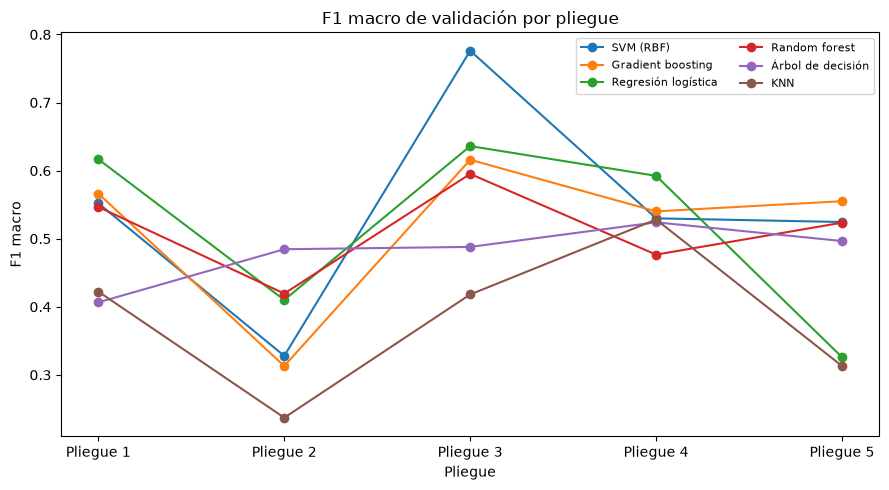

,SVM (RBF),Gradient boosting,Regresión logística,Random forest,Árbol de decisión,KNN
Pliegue 1,0.552,0.566,0.617,0.547,0.407,0.422
Pliegue 2,0.328,0.313,0.410,0.419,0.485,0.237
Pliegue 3,0.776,0.616,0.636,0.595,0.488,0.418
Pliegue 4,0.530,0.540,0.592,0.477,0.524,0.528
Pliegue 5,0.525,0.555,0.326,0.524,0.497,0.313


In [32]:
# F1 macro de validación en cada pliegue: ¿algún modelo depende de un pliegue en particular?
pliegues = pd.DataFrame({nombre: puntajes_cv[nombre]["test_f1_macro"] for nombre in orden},
                        index=[f"Pliegue {k}" for k in range(1, cv.get_n_splits() + 1)])

fig, ax = plt.subplots(figsize=(9, 5))
for nombre in orden:
    ax.plot(pliegues.index, pliegues[nombre], marker="o", label=nombre)
ax.set(title="F1 macro de validación por pliegue", xlabel="Pliegue", ylabel="F1 macro")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(FIGURAS / "f1_pliegues.png", dpi=150, bbox_inches="tight")
plt.show()
pliegues.round(3)

**Interpretación:** el desempeño cambia mucho de un pliegue a otro y de forma parecida para casi todos los modelos. El pliegue 2 es el más difícil (F1 entre 0,24 y 0,42, salvo el árbol) y el pliegue 3 el más fácil, lo que indica que la variación depende sobre todo de qué ratones caen en cada pliegue, ya que cada uno tiene solo 11 o 12. Aun así, los modelos difieren en estabilidad: la SVM va de 0,328 a 0,776, el rango más amplio, mientras que el random forest se mantiene entre 0,419 y 0,595 y el árbol entre 0,407 y 0,524, aunque en un nivel más bajo.

### 7.2 Tabla de decisión

La tabla reúne, para cada modelo, los criterios de la elección: desempeño, estabilidad, calidad de las probabilidades, exactitud por ratón, error en el genotipo y brecha con el entrenamiento.

In [33]:
# Tabla de decisión: desempeño, estabilidad, probabilidades, nivel ratón y costo de los errores
def media(nombre, metrica, signo=1):
    return signo * puntajes_cv[nombre][f"test_{metrica}"].mean()

decision = pd.DataFrame({
    nombre: {
        "F1 macro": media(nombre, "f1_macro"),
        "DE del F1": puntajes_cv[nombre]["test_f1_macro"].std(),
        "AUC OvR": media(nombre, "auc_ovr"),
        "Log loss": media(nombre, "log_loss", -1),
        "Brier": media(nombre, "brier", -1),
        "Exactitud por ratón": tabla_raton.loc[nombre, "Exactitud por ratón"],
        "Error en genotipo": tabla_factores.loc[nombre, "Genotipo"],
        "Brecha de F1": brecha.loc[nombre, "Brecha"],
    }
    for nombre in orden
}).T.astype(float).round(3)

# Regla de una desviación estándar: modelos cuyo F1 queda dentro de una DE del mejor
umbral = decision["F1 macro"].max() - decision.loc[orden[0], "DE del F1"]
decision["Dentro de 1 DE"] = decision["F1 macro"] >= umbral
decision

,F1 macro,DE del F1,AUC OvR,Log loss,Brier,Exactitud por ratón,Error en genotipo,Brecha de F1,Dentro de 1 DE
SVM (RBF),0.542,0.142,0.875,1.483,0.653,0.621,0.207,0.350,True
Gradient boosting,0.518,0.106,0.844,1.976,0.712,0.603,0.259,0.482,True
Regresión logística,0.516,0.125,0.884,3.398,0.770,0.586,0.259,0.484,True
Random forest,0.512,0.060,0.901,1.235,0.596,0.603,0.241,0.487,True
Árbol de decisión,0.480,0.039,0.842,4.696,0.769,0.586,0.276,0.302,True
KNN,0.384,0.100,0.785,9.718,0.818,0.397,0.310,0.616,False


**Interpretación:** según la regla de una desviación estándar, cinco modelos quedan empatados con la SVM, cuyo F1 de 0,542 menos su desviación de 0,142 deja el umbral en 0,400; solo KNN queda por fuera (James et al., 2023). Por lo tanto, la elección entre los cinco depende de los demás criterios, y de ellos surgen dos finalistas:

- **SVM (RBF):** tiene el mayor F1 macro (0,542), la mayor exactitud por ratón (0,621) y el menor error en el genotipo (20,7 %), pero también la mayor variación entre pliegues (± 0,142).
- **Random forest:** tiene el mejor AUC (0,901), las mejores probabilidades (log loss de 1,235 y Brier de 0,596) y la menor desviación entre los modelos con F1 mayor que 0,5 (± 0,060).

Los otros tres se descartan por razones concretas. La regresión logística y el árbol tienen un log loss peor que el de la línea base, lo que los hace poco útiles si las probabilidades se usan para decidir, y el gradient boosting no supera a ninguno de los dos finalistas en ningún criterio. En cuanto a la interpretabilidad, ninguno de los finalistas se puede leer directamente como la regresión logística o el árbol, por lo que su interpretación se hace con la importancia por permutación de la sección 9.

### 7.3 Calibración del modelo candidato 

Como el random forest es poco confiado (sección 5.6), sus probabilidades se pueden corregir con `CalibratedClassifierCV`, que ajusta una función sigmoide sobre las probabilidades de cada clase (Platt, 1999); con pocos datos, la sigmoide es preferible a la regresión isotónica, que necesita muchas observaciones (Niculescu-Mizil & Caruana, 2005). Para que la calibración no introduzca fuga, se evalúa con una validación anidada: en cada pliegue externo, la calibración usa a su vez una validación interna agrupada por ratón, de modo que nunca ve al ratón que se evalúa.

In [34]:
def metricas_desde_proba(y, proba):
    """Las mismas métricas de METRICAS calculadas a partir de probabilidades, sobre todas las réplicas."""
    pred = np.array(CLASES)[proba.argmax(axis=1)]
    return pd.Series({
        "accuracy": accuracy_score(y, pred),
        "balanced_accuracy": balanced_accuracy_score(y, pred),
        "precision_macro": precision_score(y, pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y, pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y, pred, average="macro", zero_division=0),
        "auc_ovr": roc_auc_score(y, proba, multi_class="ovr", labels=CLASES),
        "log_loss": log_loss(y, proba, labels=CLASES),
        "brier": brier_score_loss(y, proba, labels=CLASES),
    })

In [35]:
def evaluar_calibracion(modelo, metodo="sigmoid"):
    """Probabilidades fuera de pliegue del modelo calibrado. En cada pliegue externo, la calibración
    usa una validación interna también agrupada por ratón, de modo que nunca ve al ratón evaluado."""
    proba = np.zeros((len(y_train), len(CLASES)))
    for idx_ent, idx_val in cv.split(X_train, y_train, groups=grupos_train):
        cv_interna = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEMILLA)
        divisiones = list(cv_interna.split(X_train.iloc[idx_ent], y_train.iloc[idx_ent],
                                           groups=grupos_train.iloc[idx_ent]))
        calibrado = CalibratedClassifierCV(clone(modelo), method=metodo, cv=divisiones)
        calibrado.fit(X_train.iloc[idx_ent], y_train.iloc[idx_ent])
        proba[idx_val] = calibrado.predict_proba(X_train.iloc[idx_val])
    return proba


CANDIDATO = "Random forest"
proba_calibrada = evaluar_calibracion(modelos[CANDIDATO])

comparacion_calibracion = pd.DataFrame({
    f"{CANDIDATO} sin calibrar": metricas_desde_proba(y_train, probas_cv[CANDIDATO]),
    f"{CANDIDATO} calibrado (sigmoide)": metricas_desde_proba(y_train, proba_calibrada),
}).T.round(3)
comparacion_calibracion

,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,auc_ovr,log_loss,brier
Random forest sin calibrar,0.549,0.545,0.540,0.545,0.541,0.885,1.234,0.597
Random forest calibrado (sigmoide),0.531,0.526,0.518,0.526,0.517,0.844,1.404,0.640


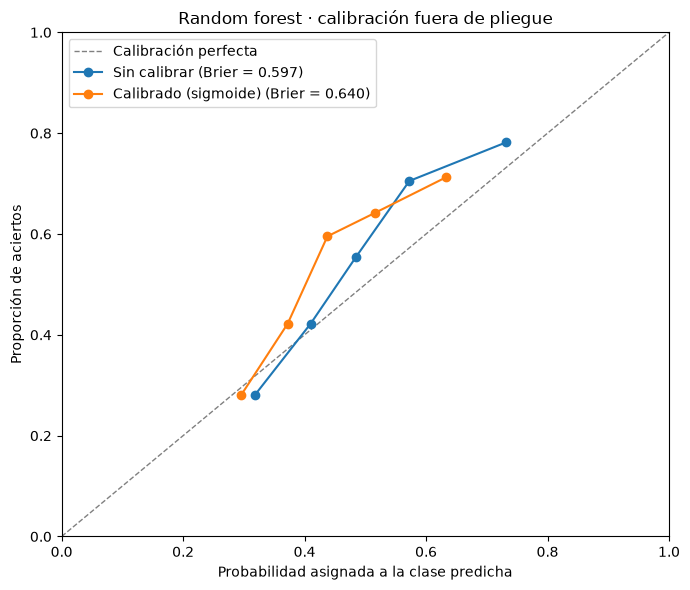

In [36]:
# Curva de calibración de la clase predicha, antes y después de calibrar
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1, label="Calibración perfecta")
for etiqueta, proba in [("Sin calibrar", probas_cv[CANDIDATO]), ("Calibrado (sigmoide)", proba_calibrada)]:
    pred = np.array(CLASES)[proba.argmax(axis=1)]
    acierto = (pred == y_train.to_numpy()).astype(int)
    real, confianza = calibration_curve(acierto, proba.max(axis=1), n_bins=5, strategy="quantile")
    brier = brier_score_loss(y_train, proba, labels=CLASES)
    ax.plot(confianza, real, marker="o", label=f"{etiqueta} (Brier = {brier:.3f})")
ax.set(title=f"{CANDIDATO} · calibración fuera de pliegue", xlabel="Probabilidad asignada a la clase predicha",
       ylabel="Proporción de aciertos", xlim=(0, 1), ylim=(0, 1))
ax.legend()
fig.tight_layout()
fig.savefig(FIGURAS / "calibracion_candidato.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:** la calibración empeora todas las métricas del random forest: el log loss sube de 1,234 a 1,404, el Brier de 0,597 a 0,640, el AUC baja de 0,885 a 0,844 y el F1 macro de 0,541 a 0,517. La razón es el tamaño de la muestra. En cada pliegue externo, la calibración interna divide a unos 46 ratones en 4 partes, de modo que cada sigmoide se ajusta con apenas 11 o 12 ratones, y el ruido de esa estimación pesa más que la corrección. Además, `CalibratedClassifierCV` calibra cada clase por separado y luego renormaliza, lo que altera el orden de las probabilidades entre clases y explica la caída del AUC. Por lo tanto, se conserva el random forest sin calibrar, y en la SVM se mantiene la calibración de Platt que ya trae `probability=True`.

### 7.4 Regla de decisión según el costo de los errores 

En un problema binario, el umbral de 0,5 se reemplaza por uno que minimiza el costo esperado. Con 8 clases, el equivalente es elegir, para cada réplica, la clase con menor costo esperado dadas sus probabilidades, en lugar de la de mayor probabilidad (Elkan, 2001). Esto requiere una matriz de costos y probabilidades calibradas. 

Los costos se fijan según el factor errado, con tres supuestos explícitos. Primero, confundir el **genotipo** cuesta 3, porque atribuiría a un ratón control el perfil del modelo de síndrome de Down, o al revés, que es la distinción de fondo del estudio (Reeves et al., 1995). Segundo, confundir la **conducta** cuesta 2, porque equivale a no reconocer la huella proteica del aprendizaje (Ahmed et al., 2015). Tercero, confundir el **tratamiento** cuesta 1, porque el efecto de la memantina se espera más sutil. El costo de un error es la suma de los factores en que difiere, de modo que confundir las tres partes cuesta 6. Las reglas se comparan en los dos finalistas de la sección 7.2, con sus probabilidades fuera de pliegue. El criterio se fija antes de ver los resultados: gana la combinación de modelo y regla con menor costo medio por ratón, porque el ratón es la unidad de decisión, y el F1 macro por réplica desempata. Así, la elección se hace con la validación cruzada, sin mirar la prueba.

In [37]:
# Matriz de costos: el costo de predecir la clase k cuando la real es j suma el peso de cada factor errado
def matriz_costos(peso_genotipo, peso_conducta, peso_tratamiento):
    """Costo de cada par (clase real, clase predicha) según los factores en que difieren."""
    partes = [clase.split("-") for clase in CLASES]
    pesos = np.array([peso_genotipo, peso_conducta, peso_tratamiento])
    return pd.DataFrame([[pesos @ (np.array(r) != np.array(p)) for p in partes] for r in partes],
                        index=CLASES, columns=CLASES)


def decidir_por_costo(proba, costos):
    """Elige, para cada réplica, la clase con menor costo esperado dado sus probabilidades."""
    return np.array(CLASES)[(proba @ costos.to_numpy()).argmin(axis=1)]


COSTOS = matriz_costos(peso_genotipo=3, peso_conducta=2, peso_tratamiento=1)
COSTOS

,c-CS-m,c-CS-s,c-SC-m,c-SC-s,t-CS-m,t-CS-s,t-SC-m,t-SC-s
c-CS-m,0,1,2,3,3,4,5,6
c-CS-s,1,0,3,2,4,3,6,5
c-SC-m,2,3,0,1,5,6,3,4
c-SC-s,3,2,1,0,6,5,4,3
t-CS-m,3,4,5,6,0,1,2,3
t-CS-s,4,3,6,5,1,0,3,2
t-SC-m,5,6,3,4,2,3,0,1
t-SC-s,6,5,4,3,3,2,1,0


In [38]:
# Cada regla se aplica a las probabilidades fuera de pliegue de los dos finalistas, por réplica y por ratón
def costo_medio(y, pred, costos):
    """Costo promedio de las predicciones según la matriz de costos."""
    return np.mean([costos.loc[r, p] for r, p in zip(y, pred)])


def aplicar_regla(proba, costos):
    """Máxima probabilidad si no hay matriz de costos; si la hay, mínimo costo esperado."""
    return np.array(CLASES)[proba.argmax(axis=1)] if costos is None else decidir_por_costo(proba, costos)


FINALISTAS = ["SVM (RBF)", "Random forest"]
REGLAS = {
    "Máxima probabilidad": None,
    "Costo por factores 1-1-1": matriz_costos(1, 1, 1),
    "Costo por factores 3-2-1": COSTOS,
}

filas = {}
for modelo in FINALISTAS:
    # Probabilidades promedio de las réplicas de cada ratón
    promedio = pd.DataFrame(probas_cv[modelo], columns=CLASES).groupby(grupos_train.to_numpy()).mean()
    real_raton = y_train.groupby(grupos_train.to_numpy()).first().loc[promedio.index].astype(str)
    for regla, costos in REGLAS.items():
        pred = aplicar_regla(probas_cv[modelo], costos)
        pred_raton = pd.Series(aplicar_regla(promedio.to_numpy(), costos), index=promedio.index)
        filas[(modelo, regla)] = {
            "Costo medio por ratón (3-2-1)": costo_medio(real_raton, pred_raton, COSTOS),
            "Exactitud por ratón": accuracy_score(real_raton, pred_raton),
            "Costo medio por réplica (3-2-1)": costo_medio(y_train.astype(str), pred, COSTOS),
            "F1 macro por réplica": f1_score(y_train, pred, average="macro"),
            **{f"Ratones con error en {k.lower()}": v
               for k, v in errores_por_factor(real_raton, pred_raton).items()},
        }
tabla_reglas = pd.DataFrame(filas).T.round(3)

# Criterio fijado de antemano: menor costo medio por ratón; el F1 macro por réplica desempata
FINAL, REGLA_FINAL = tabla_reglas.sort_values(["Costo medio por ratón (3-2-1)", "F1 macro por réplica"],
                                              ascending=[True, False]).index[0]
print(f"Combinación elegida: {FINAL} con la regla «{REGLA_FINAL}»")
tabla_reglas

Combinación elegida: SVM (RBF) con la regla «Máxima probabilidad»


Costo medio por ratón (3-2-1)  \
SVM (RBF)     Máxima probabilidad                               0.879   
              Costo por factores 1-1-1                          0.914   
              Costo por factores 3-2-1                          0.914   
Random forest Máxima probabilidad                               1.000   
              Costo por factores 1-1-1                          1.034   
              Costo por factores 3-2-1                          1.034   

                                        Exactitud por ratón  \
SVM (RBF)     Máxima probabilidad                     0.621   
              Costo por factores 1-1-1                0.638   
              Costo por factores 3-2-1                0.638   
Random forest Máxima probabilidad                     0.603   
              Costo por factores 1-1-1                0.603   
              Costo por factores 3-2-1                0.603   

                                        Costo medio por réplica (3-2-1)  \
SVM (RBF)     Máxima probabilidad                                 1.115   
              Costo por factores 1-1-1                            1.051   
              Costo por factores 3-2-1                            1.051   
Random forest Máxima probabilidad                                 1.186   
              Costo por factores 1-1-1                            1.151   
              Costo por factores 3-2-1                            1.151   

                                        F1 macro por réplica  \
SVM (RBF)     Máxima probabilidad                      0.536   
              Costo por factores 1-1-1                 0.554   
              Costo por factores 3-2-1                 0.554   
Random forest Máxima probabilidad                      0.541   
              Costo por factores 1-1-1                 0.551   
              Costo por factores 3-2-1                 0.551   

                                        Ratones con error en genotipo  \
SVM (RBF)     Máxima probabilidad                               0.207   
              Costo por factores 1-1-1                          0.241   
              Costo por factores 3-2-1                          0.241   
Random forest Máxima probabilidad                               0.241   
              Costo por factores 1-1-1                          0.259   
              Costo por factores 3-2-1                          0.259   

                                        Ratones con error en conducta  \
SVM (RBF)     Máxima probabilidad                               0.017   
              Costo por factores 1-1-1                          0.000   
              Costo por factores 3-2-1                          0.000   
Random forest Máxima probabilidad                               0.000   
              Costo por factores 1-1-1                          0.000   
              Costo por factores 3-2-1                          0.000   

                                        Ratones con error en tratamiento  
SVM (RBF)     Máxima probabilidad                                  0.224  
              Costo por factores 1-1-1                             0.190  
              Costo por factores 3-2-1                             0.190  
Random forest Máxima probabilidad                                  0.276  
              Costo por factores 1-1-1                             0.259  
              Costo por factores 3-2-1                             0.259

**Interpretación:** con estas probabilidades, las matrices 1-1-1 y 3-2-1 producen exactamente las mismas decisiones, lo que indica que la jerarquía elegida entre los factores no cambia el resultado; lo que importa es pasar de la máxima probabilidad a una regla que considere la estructura de las clases. En ambos finalistas, la regla de costo mejora el desempeño por réplica: en la SVM, el costo medio baja de 1,115 a 1,051 y el F1 macro sube de 0,536 a 0,554. Sin embargo, a nivel de ratón el efecto se invierte, ya que el costo medio de la SVM sube de 0,879 a 0,914: la regla elimina el único error de conducta, pero agrega dos ratones con error en el genotipo (del 20,7 % al 24,1 %), que es el error que más cuesta. 

Como el criterio fijado de antemano es el menor costo medio por ratón, la combinación elegida es la **SVM con la regla de máxima probabilidad** (costo de 0,879, frente a 1,000 del mejor random forest). En consecuencia, la regla de costo no se adopta, porque al promediar las 15 réplicas de cada ratón las probabilidades ya se concentran en la clase correcta con más frecuencia, y el ajuste por costos termina intercambiando errores leves por errores graves.

### 7.5 Modelo final 

El modelo final es la **SVM con kernel RBF** (C = 100, gamma = 0,00001, clases balanceadas), que clasifica cada ratón con la clase de mayor probabilidad promedio entre sus réplicas. La decisión se apoya en cuatro argumentos, todos obtenidos en la validación cruzada: está entre los modelos empatados según la regla de una desviación estándar, tiene el mayor F1 macro y la mayor exactitud por ratón, comete menos errores en el genotipo que cualquier otro modelo, y obtiene el menor costo medio por ratón entre las seis combinaciones evaluadas. Su principal debilidad es la variación entre pliegues, que se tiene en cuenta al interpretar el resultado en prueba. El random forest queda como alternativa cuando se necesiten probabilidades mejor calibradas.

## 8. Evaluación final en prueba

El modelo final, la SVM con la regla de máxima probabilidad, ya fue reajustado con todo el entrenamiento por `refit`, y se evalúa una sola vez sobre los 14 ratones de prueba, junto con la línea base. Ninguna decisión anterior usó estos ratones.

In [39]:
# Modelo final elegido en la sección 7.4, ya reajustado con todo el entrenamiento, y su regla de decisión
modelo_final = modelos[FINAL]
costos_final = REGLAS[REGLA_FINAL]

# Única evaluación en prueba: modelo final y línea base, ambos ajustados con todo el entrenamiento
linea_base_final = DummyClassifier(strategy="prior").fit(X_train, y_train)
proba_test = modelo_final.predict_proba(X_test)
proba_base = linea_base_final.predict_proba(X_test)

tabla_prueba = pd.DataFrame({
    FINAL: metricas_desde_proba(y_test, proba_test),
    "Línea base (prior)": metricas_desde_proba(y_test, proba_base),
}).T
tabla_prueba["costo_medio_321"] = [costo_medio(y_test.astype(str), aplicar_regla(p, costos_final), COSTOS)
                                   for p in (proba_test, proba_base)]
print(f"Modelo final: {FINAL} · regla: {REGLA_FINAL}")
tabla_prueba.round(3)

Modelo final: SVM (RBF) · regla: Máxima probabilidad


,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,auc_ovr,log_loss,brier,costo_medio_321
SVM (RBF),0.676,0.650,0.616,0.650,0.598,0.929,0.977,0.522,0.586
Línea base (prior),0.143,0.125,0.018,0.125,0.031,0.500,2.079,0.875,2.786


Ratones de prueba bien clasificados: 10 de 14 | costo medio por ratón: 0.571
Genotipo       0.143
Conducta       0.000
Tratamiento    0.143


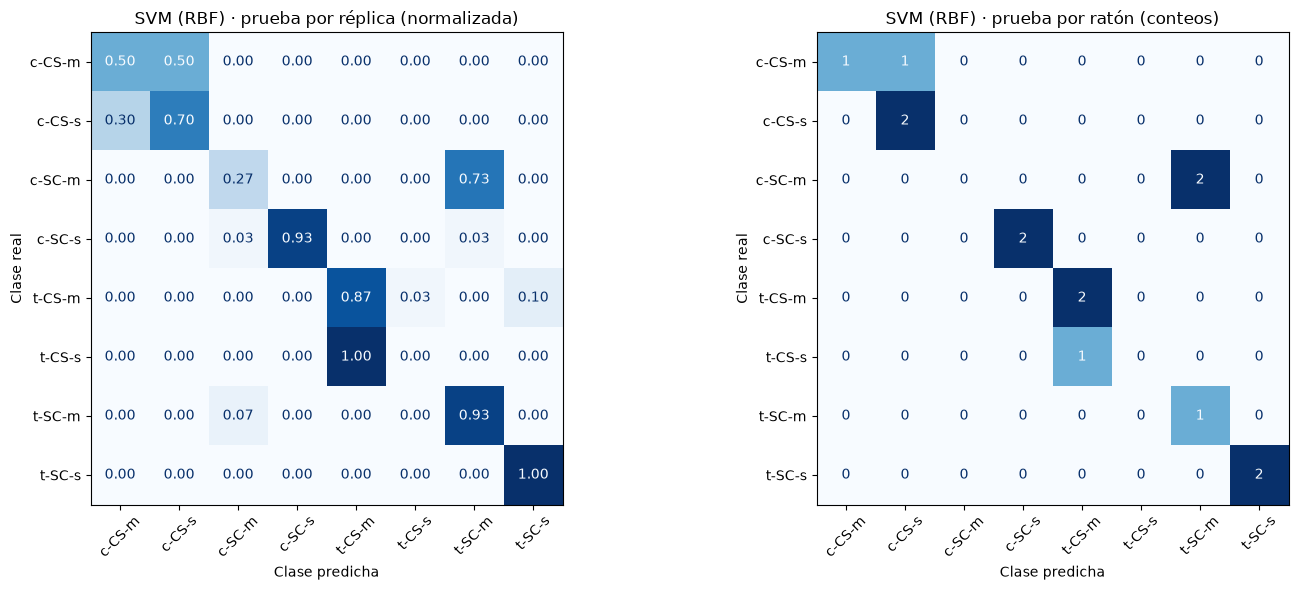

,Clase real,Clase predicha
311,c-CS-m,c-CS-s
322,c-CS-m,c-CS-m
3416,t-CS-m,t-CS-m
3419,c-SC-m,t-SC-m
3480,c-CS-s,c-CS-s
3489,c-SC-s,c-SC-s
3498,t-CS-s,t-CS-m
3513,t-SC-s,t-SC-s
3516,c-SC-s,c-SC-s
3605,t-SC-m,t-SC-m


In [40]:
# Prueba por ratón: promedio de las probabilidades de las 15 réplicas y regla de decisión elegida
promedio_test = pd.DataFrame(proba_test, columns=CLASES).groupby(grupos_test.to_numpy()).mean()
real_test = y_test.groupby(grupos_test.to_numpy()).first().loc[promedio_test.index].astype(str)
pred_test = pd.Series(aplicar_regla(promedio_test.to_numpy(), costos_final), index=promedio_test.index)

print(f"Ratones de prueba bien clasificados: {(real_test == pred_test).sum()} de {len(real_test)} | "
      f"costo medio por ratón: {costo_medio(real_test, pred_test, COSTOS):.3f}")
print(errores_por_factor(real_test, pred_test).round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ConfusionMatrixDisplay.from_predictions(y_test, aplicar_regla(proba_test, costos_final), labels=CLASES, normalize="true",
                                        values_format=".2f", cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set(title=f"{FINAL} · prueba por réplica (normalizada)", xlabel="Clase predicha", ylabel="Clase real")
ConfusionMatrixDisplay.from_predictions(real_test, pred_test, labels=CLASES, cmap="Blues", colorbar=False,
                                        ax=axes[1])
axes[1].set(title=f"{FINAL} · prueba por ratón (conteos)", xlabel="Clase predicha", ylabel="Clase real")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(FIGURAS / "confusion_prueba.png", dpi=150, bbox_inches="tight")
plt.show()
pd.DataFrame({"Clase real": real_test, "Clase predicha": pred_test})

**Interpretación:** en prueba, la SVM obtiene una exactitud de 0,676, un F1 macro de 0,598 y un AUC de 0,929, frente a 0,143, 0,031 y 0,500 de la línea base. Sus probabilidades también superan a la referencia, con un log loss de 0,977 y un Brier de 0,522, frente a 2,079 y 0,875. Estos valores son algo mejores que la media de la validación cruzada (F1 de 0,542), pero quedan dentro del rango entre pliegues (de 0,328 a 0,776). Además, con 14 ratones, un solo animal cambia la exactitud por ratón en 7 puntos, de modo que la diferencia es compatible con la variación esperada y no sugiere fuga de información. 

A nivel de ratón, el modelo clasifica bien 10 de los 14, con un costo medio de 0,571 frente a 0,879 en la validación. Los cuatro errores repiten los patrones de la sección 6. Ninguno está en la conducta. Dos están en el genotipo, y son los dos ratones `c-SC-m` predichos como `t-SC-m`, la misma confusión entre controles y trisómicos tratados con memantina que apareció en la validación. Los otros dos están en el tratamiento: un ratón `c-CS-m` predicho como `c-CS-s`, y el único ratón `t-CS-s` de prueba predicho como `t-CS-m`, es decir, un ratón con aprendizaje fallido clasificado como rescatado.

## 9. Interpretación, ficha del modelo y conclusiones

### 9.1 Importancia de las proteínas

La importancia por permutación mide cuánto cae el F1 macro en prueba cuando se desordenan los valores de una proteína, rompiendo su relación con la clase (Breiman, 2001). A diferencia de la importancia interna del random forest, se calcula sobre ratones que el modelo no vio y no favorece a las variables con más valores distintos.

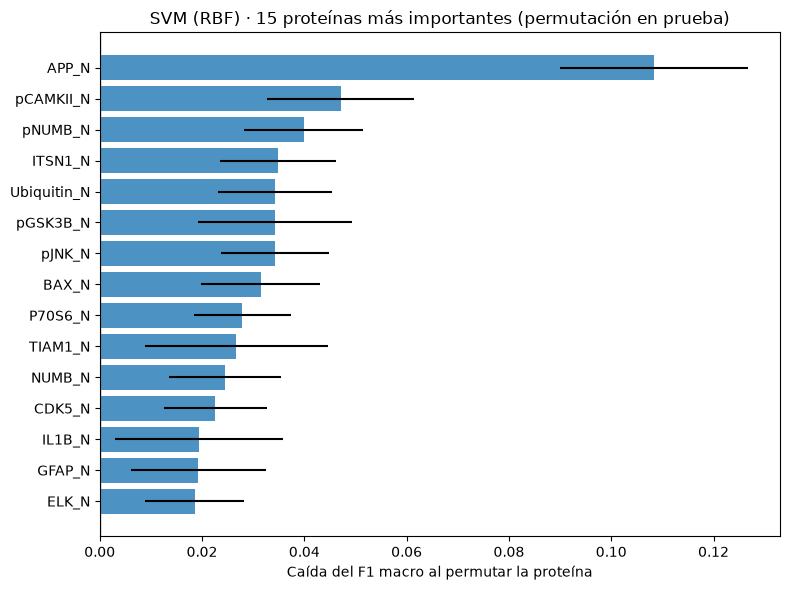

,media,de,Reportada por Higuera et al. (2015)
APP_N,0.108,0.018,sí
pCAMKII_N,0.047,0.014,sí
pNUMB_N,0.040,0.012,sí
ITSN1_N,0.035,0.011,sí
Ubiquitin_N,0.034,0.011,sí
pGSK3B_N,0.034,0.015,sí
pJNK_N,0.034,0.011,no
BAX_N,0.031,0.012,no
P70S6_N,0.028,0.009,no
TIAM1_N,0.027,0.018,no


In [41]:
# Importancia por permutación en prueba: cuánto cae el F1 macro al desordenar cada proteína
importancia = permutation_importance(modelo_final, X_test, y_test, scoring="f1_macro",
                                     n_repeats=30, random_state=SEMILLA, n_jobs=-1)
tabla_importancia = (pd.DataFrame({"media": importancia.importances_mean, "de": importancia.importances_std},
                                  index=PROTEINAS)
                       .sort_values("media", ascending=False))

top = tabla_importancia.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top["media"], xerr=top["de"], color="tab:blue", alpha=0.8)
ax.axvline(0, color="gray", linewidth=1)
ax.set(title=f"{FINAL} · 15 proteínas más importantes (permutación en prueba)",
       xlabel="Caída del F1 macro al permutar la proteína", ylabel=None)
fig.tight_layout()
fig.savefig(FIGURAS / "importancia_permutacion.png", dpi=150, bbox_inches="tight")
plt.show()
# Proteínas que Higuera et al. (2015) reportan en sus comparaciones entre clases
# (aprendizaje normal, aprendizaje fallido, rescate con memantina, efecto de la memantina y genotipo)
REPORTADAS = {"BRAF_N", "CaNA_N", "CDK5_N", "DYRK1A_N", "GFAP_N", "ITSN1_N", "pERK_N", "pGSK3B_N", "pNUMB_N",
              "S6_N", "SOD1_N", "MTOR_N", "P38_N", "NR2B_N", "pP70S6_N", "GluR4_N", "RRP1_N", "GluR3_N",
              "P3525_N", "Ubiquitin_N", "pNR2A_N", "pPKCAB_N", "pMTOR_N", "pPKCG_N", "ARC_N", "ERBB4_N",
              "SNCA_N", "BAD_N", "pRSK_N", "APP_N", "BDNF_N", "pCAMKII_N", "PKCA_N", "pNR1_N"}
assert REPORTADAS <= set(PROTEINAS)
tabla_top = tabla_importancia.head(15).round(3)
tabla_top["Reportada por Higuera et al. (2015)"] = ["sí" if p in REPORTADAS else "no" for p in tabla_top.index]
tabla_top

**Interpretación:** la proteína más importante para la SVM es `APP_N`: al desordenarla, el F1 macro cae en 0,108, más del doble que la siguiente, `pCAMKII_N` (0,047). Le siguen `pNUMB_N`, `ITSN1_N`, `Ubiquitin_N` y `pGSK3B_N`. De las 15 proteínas más importantes, 8 están entre las que Higuera et al. (2015) reportan en sus comparaciones entre clases, entre ellas APP e ITSN1, codificadas en el cromosoma 21 humano y, por tanto, en copia extra en los ratones Ts65Dn, y Ubiquitin, que esos autores asocian al rescate del aprendizaje con memantina. Esta coincidencia respalda que el modelo se apoya en proteínas con sentido biológico y no en artefactos de la medición. 

Sin embargo, hay dos cautelas. Primero, `SOD1_N`, la proteína de la primera división del árbol, no aparece entre las más importantes para la SVM. Esto no contradice al árbol: cuando varias proteínas están correlacionadas, desordenar una afecta poco, porque las demás la reemplazan, de modo que la importancia por permutación subestima a las proteínas redundantes. Segundo, la importancia se calcula sobre solo 14 ratones de prueba, por lo que las proteínas con importancia menor que 0,02 tienen desviaciones de su mismo orden y su posición en la tabla no es confiable.

### 9.2 Ficha del modelo

Siguiendo la propuesta de Mitchell et al. (2019), se resume el modelo final en una ficha que indica para qué sirve,
cómo se evaluó y qué no debe hacerse con él.

| Aspecto | Descripción |
|---|---|
| Modelo | SVM con kernel RBF (C = 100, gamma = 0,00001, clases balanceadas) dentro de un `Pipeline` con log, escalado e imputación KNN |
| Propósito | Identificar la condición experimental (genotipo, conducta y tratamiento) de un ratón a partir de las 76 proteínas de la corteza, promediando sus réplicas |
| Datos | 72 ratones control y Ts65Dn de Higuera et al. (2015); 58 para entrenar y 14 para la prueba final |
| Validación | Validación cruzada de 5 pliegues agrupada por ratón y estratificada por clase; prueba usada una sola vez |
| Desempeño en validación | F1 macro de 0,542 ± 0,142; exactitud por ratón de 0,621; AUC de 0,875 |
| Desempeño en prueba | F1 macro de 0,598; 10 de 14 ratones bien clasificados; AUC de 0,929 |
| Fortalezas | Reconoce la conducta casi sin errores y es el modelo con menos errores de genotipo |
| Debilidades | Confunde el tratamiento dentro del grupo estimulado (`c-CS-s` acierta 1 de 7 ratones) y varía mucho entre pliegues |
| Usos previstos | Explorar qué proteínas distinguen las condiciones del experimento y verificar la consistencia de nuevas muestras del mismo protocolo |
| Usos no previstos | No sirve para diagnosticar, ni para afirmar que una proteína causa el aprendizaje o el efecto de la memantina, ni para aplicarse a otras especies, tejidos o protocolos sin una nueva validación |

### 9.3 Conclusiones y limitaciones 

La pregunta del notebook era si se puede identificar la condición experimental de un ratón a partir de su perfil de proteínas. La respuesta es que sí, de forma parcial. Por un lado, el modelo final clasifica bien cerca del 62 % de los ratones en la validación y 10 de 14 en la prueba, cinco veces más que el azar para 8 clases, y reconoce casi sin errores si el ratón fue estimulado para aprender. Por otro lado, distinguir el genotipo y el tratamiento dentro de un mismo grupo de conducta sigue siendo difícil, sobre todo en los ratones control tratados con salina del grupo CS. Esto concuerda con la hipótesis de la sección 1: el perfil proteico cambia con la condición experimental, pero el aprendizaje deja una huella más fuerte que la trisomía o la memantina. 

Además, el trabajo deja tres aprendizajes metodológicos. Primero, validar por filas habría reportado exactitudes cercanas a 1 (sección 3), por lo que la partición por ratón es indispensable en datos con réplicas. Segundo, varios modelos empatan en desempeño, y la elección depende de criterios adicionales como la calidad de las probabilidades, la estabilidad y el costo de cada error. Tercero, la calibración y las reglas de costo no siempre mejoran el resultado: con 58 ratones, la calibración agrega más ruido que corrección, y la regla de costo mejora el desempeño por réplica, pero no por ratón. 

Por otra parte, el análisis tiene cuatro limitaciones. Primero, el tamaño efectivo es de 72 ratones, unos 6 por clase en cada pliegue de entrenamiento, lo que explica la gran variación entre pliegues. Segundo, la prueba tiene uno o dos ratones por clase, por lo que las métricas por clase en prueba son poco precisas. Tercero, los hiperparámetros se eligieron con los mismos pliegues con que se reportan las métricas de validación, lo que puede hacerlas algo optimistas; una validación cruzada anidada corregiría este sesgo (Varma & Simon, 2006). Cuarto, la matriz de costos se basa en supuestos sobre la gravedad de cada error, que otro investigador podría fijar de otra manera. 

Para la Actividad 4, estos resultados permiten contar una historia completa: la pseudorreplicación como riesgo central, la conducta como la señal más clara en las proteínas, y las proteínas asociadas al cromosoma 21 como base de la clasificación.

## Referencias

Ahmed, M. M., Dhanasekaran, A. R., Block, A., Tong, S., Costa, A. C. S., Stasko, M., & Gardiner, K. J. (2015). Protein dynamics associated with failed and rescued learning in the Ts65Dn mouse model of Down syndrome. *PLOS ONE, 10*(3), e0119491. https://doi.org/10.1371/journal.pone.0119491

Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://doi.org/10.1023/A:1010933404324

Breiman, L., Friedman, J. H., Olshen, R. A., & Stone, C. J. (1984). *Classification and regression trees*. Wadsworth.

Brier, G. W. (1950). Verification of forecasts expressed in terms of probability. *Monthly Weather Review, 78*(1), 1–3. https://doi.org/10.1175/1520-0493(1950)078<0001:VOFEIT>2.0.CO;2

Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning, 20*(3), 273–297. https://doi.org/10.1007/BF00994018

Cover, T., & Hart, P. (1967). Nearest neighbor pattern classification. *IEEE Transactions on Information Theory, 13*(1), 21–27. https://doi.org/10.1109/TIT.1967.1053964

Elkan, C. (2001). The foundations of cost-sensitive learning. En *Proceedings of the 17th International Joint Conference on Artificial Intelligence* (pp. 973–978). Morgan Kaufmann.

Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232. https://doi.org/10.1214/aos/1013203451

Higuera, C., Gardiner, K. J., & Cios, K. J. (2015). Self-organizing feature maps identify proteins critical to learning in a mouse model of Down syndrome. *PLOS ONE, 10*(6), e0129126. https://doi.org/10.1371/journal.pone.0129126

James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An introduction to statistical learning: With applications in Python*. Springer. https://doi.org/10.1007/978-3-031-38747-0

Kuhn, M., & Johnson, K. (2019). *Feature engineering and selection: A practical approach for predictive models*. CRC Press.

Mitchell, M., Wu, S., Zaldivar, A., Barnes, P., Vasserman, L., Hutchinson, B., Spitzer, E., Raji, I. D., & Gebru, T. (2019). Model cards for model reporting. En *Proceedings of the Conference on Fairness, Accountability, and Transparency* (pp. 220–229). ACM. https://doi.org/10.1145/3287560.3287596

Niculescu-Mizil, A., & Caruana, R. (2005). Predicting good probabilities with supervised learning. En *Proceedings of the 22nd International Conference on Machine Learning* (pp. 625–632). ACM. https://doi.org/10.1145/1102351.1102430

Platt, J. C. (1999). Probabilistic outputs for support vector machines and comparisons to regularized likelihood methods. En A. J. Smola, P. Bartlett, B. Schölkopf, & D. Schuurmans (Eds.), *Advances in large margin classifiers* (pp. 61–74). MIT Press.

Reeves, R. H., Irving, N. G., Moran, T. H., Wohn, A., Kitt, C., Sisodia, S. S., Schmidt, C., Bronson, R. T., & Davisson, M. T. (1995). A mouse model for Down syndrome exhibits learning and behaviour deficits. *Nature Genetics, 11*(2), 177–184. https://doi.org/10.1038/ng1095-177

Roberts, D. R., Bahn, V., Ciuti, S., Boyce, M. S., Elith, J., Guillera-Arroita, G., Hauenstein, S., Lahoz-Monfort, J. J., Schröder, B., Thuiller, W., Warton, D. I., Wintle, B. A., Hartig, F., & Dormann, C. F. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography, 40*(8), 913–929. https://doi.org/10.1111/ecog.02881

Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE, 10*(3), e0118432. https://doi.org/10.1371/journal.pone.0118432

Sweatt, J. D. (2004). Mitogen-activated protein kinases in synaptic plasticity and memory. *Current Opinion in Neurobiology, 14*(3), 311–317. https://doi.org/10.1016/j.conb.2004.04.001

Varma, S., & Simon, R. (2006). Bias in error estimation when using cross-validation for model selection. *BMC Bioinformatics, 7*, 91. https://doi.org/10.1186/1471-2105-7-91